# Fine-tuning de BERT pour la classification de sentiment (SST-2)
**Module 7 · The Transformer & BERT — Hands-on**

**Réalisé par :** HABBANI Mohammed, BEN ALLA Ilyas et ETTAHIRI Mohammed-Yassine &nbsp;·&nbsp; **Date :** novembre 2026

---

## 1 · Introduction et objectifs
La consigne du cours : **fine-tuner `bert-base-uncased` sur SST-2 (GLUE)**, **battre une baseline TF-IDF + régression logistique**, atteindre **~92 % d'accuracy en validation** et **comprendre les erreurs**.

| Exigence de la consigne | Réalisation dans ce notebook | Section |
|---|---|---|
| Dataset SST-2 (GLUE), via Hugging Face | `load_dataset("glue", "sst2")`, splits officiels, aucun fichier local | 3 |
| Modèle `bert-base-uncased` | Fine-tuning PyTorch (boucle personnalisée, AdamW, warm-up, clipping, précision mixte) | 6 – 7 |
| Outils `transformers`, `datasets`, PyTorch, scikit-learn | Versions affichées en section 2 | 2 |
| Battre la baseline TF-IDF + LogReg | Comparaison appariée, test de McNemar, IC bootstrap | 5, 8 |
| ~92 % de validation | Critère vérifié automatiquement | 8, 10 |
| Analyser les erreurs | Sous-groupes avec intervalles de confiance, exemples annotés, hypothèses séparées des observations | 9 |

### Protocole d'évaluation (point méthodologique central)
Le split **test officiel de GLUE n'est pas étiqueté publiquement** (les labels valent `-1`, l'évaluation se fait via le serveur GLUE). Il ne peut donc servir ni à choisir ni à mesurer quoi que ce soit : il est chargé uniquement pour vérifier cette absence d'étiquettes, puis écarté. Pour ne **jamais** régler un choix sur le jeu qui sert à rapporter la performance, on utilise trois jeux disjoints :

| Jeu | Origine | Rôle |
|---|---|---|
| `train_fit` | ~95 % du train officiel (découpage **par groupes de phrases**, sans fuite — section 4) | apprentissage |
| `dev` | ~5 % du train officiel (groupes entiers mis de côté) | **sélection** : hyper-paramètres de la baseline, meilleure époque de BERT |
| `validation` | split **validation officiel** (872 phrases) | **évaluation finale, une seule fois** par modèle ; tests statistiques et analyse d'erreurs |

> Tous les chiffres de ce notebook sont **calculés à l'exécution** ; aucun résultat n'est écrit en dur.

### Reproduire l'expérience (Google Colab)
1. *Exécution → Modifier le type d'exécution → **GPU (T4)***.
2. *Exécution → Tout exécuter*. Aucune autre action n'est nécessaire (aucun fichier à importer, données et modèle téléchargés automatiquement). Durée ≈ 15–25 min sur T4.
3. La dernière cellule crée `results_sst2.zip` (métriques, prédictions, figures) et le télécharge.

### Compléments au travail initial
Le travail initial (sections 1 à 10) est conservé tel quel. Les cellules ajoutées traitent les points du cours qui restaient ouverts. Chaque ajout suit le même protocole : sélection sur `dev`, validation officielle évaluée une seule fois par modèle, chiffres calculés à l'exécution.

| Ajout | Raison | Section |
|---|---|---|
| Tokenisation WordPiece détaillée | étape 3 de la feuille de route du cours | 6.1 |
| Fine-tuning répété sur trois graines | ne pas conclure sur une seule graine | 7 |
| BERT gelé + régression logistique | bonus du cours : mesurer l'apport du fine-tuning complet | 7.1 |
| DistilBERT (option, désactivée par défaut) | option CPU citée dans le cours | 7.2 |
| Comparaison élargie et coût d'inférence | situer chaque modèle en accuracy et en coût | 8.1 |
| Hypothèse H4 et écarts entre sous-groupes | hypothèse laissée ouverte en section 9 | 9.5 |
| Phrases personnelles et paires minimales | étape 6 du cours, test contrôlé de H1 | 9.6 |
| Calibration des probabilités | éclairer H3 et les erreurs très confiantes | 9.7 |
| Dix erreurs regroupées par cause | livrable 4 du cours | 9.8 et 9.9 |
| Synthèse reliée au MLM, au `[CLS]` et au fine-tuning | livrable 5 du cours | 10.3 et 10.4 |

Avec ces ajouts, l'exécution complète dure environ 50 minutes sur un GPU T4 de Colab, dont environ 25 pour les deux graines supplémentaires.

## 2 · Environnement et reproductibilité
Les dépendances sont installées avec des versions minimales explicites, puis toute la configuration est regroupée dans **une seule cellule**. Les graines sont fixées pour Python, NumPy et PyTorch ; le CPU/GPU et le type de précision mixte sont détectés automatiquement.

In [1]:
# Installation explicite (Colab : aucun redémarrage nécessaire en général ; sinon Exécution -> Redémarrer la session)
%pip install -q "transformers>=4.44" "datasets>=2.19" "scikit-learn>=1.3" "scipy>=1.11" "pandas>=2.0" "seaborn>=0.13" "matplotlib>=3.7"

In [2]:
import os, re, gc, json, time, random, platform, warnings, importlib, shutil
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 110)
os.environ["TOKENIZERS_PARALLELISM"] = "false"
BLUE, ORANGE = "#4C72B0", "#DD8452"          # baseline = bleu, BERT = orange (toutes les figures)

# =============================== CONFIGURATION ===============================
SEED          = 42
MODEL_NAME    = "bert-base-uncased"          # option CPU : "distilbert-base-uncased"
EPOCHS        = 3
BATCH_SIZE    = 32
EVAL_BATCH    = 128
LR            = 2e-5
WEIGHT_DECAY  = 0.01
WARMUP_RATIO  = 0.1
MAX_LEN       = 128
GRAD_CLIP     = 1.0
DEV_FRACTION  = 0.05                          # part du train officiel (en groupes de phrases) réservée à la sélection
MAX_TRAIN_SAMPLES = None                      # None = tout le train_fit ; un entier = essai rapide (CPU)
RUN_BERT        = True                        # False : ne refaire que la baseline
RUN_EXTRA_SEEDS = False                       # True : répète le fine-tuning avec EXTRA_SEEDS (+ ~12 min par graine sur T4)
EXTRA_SEEDS     = [43, 44]
SAVE_MODEL      = False                       # True : sauvegarde le meilleur modèle (poids + tokenizer, ~440 Mo)
TARGET_VAL_ACC  = 0.92                        # objectif de la consigne
N_BOOT          = 5000                        # rééchantillonnages bootstrap
# ==============================================================================

OUT = Path("results"); OUT.mkdir(exist_ok=True)
CKPT_DIR = OUT / "checkpoints"; CKPT_DIR.mkdir(exist_ok=True)

def set_seed(seed=SEED):
    """Fixe toutes les sources d'aléa (Python, NumPy, PyTorch CPU/GPU)."""
    random.seed(seed); np.random.seed(seed); os.environ["PYTHONHASHSEED"] = str(seed)
    import torch
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
set_seed()

Réglages propres aux compléments, regroupés juste après la configuration d'origine ; les cellules du travail initial ne changent pas. `RUN_EXTRA_SEEDS` passe à `True` pour répéter le fine-tuning avec deux autres graines (environ 12 minutes de plus par graine sur T4) et mesurer la part du hasard de l'entraînement dans les résultats.

In [3]:
# >>> PARAMÈTRES DES COMPLÉMENTS
# ecrase-volontairement: RUN_EXTRA_SEEDS
RUN_EXTRA_SEEDS   = True                        # section 7 : variabilité inter-graines (False dans la version initiale)
RUN_FROZEN        = True                        # section 7.1 : BERT gelé + régression logistique (bonus du cours)
FROZEN_MAX_TRAIN  = None                        # None = tout train_fit ; un entier = sous-échantillon
FROZEN_C_GRID     = [0.01, 0.1, 1, 10]          # C de la régression logistique, choisi sur dev
RUN_DISTILBERT    = False                       # section 7.2 : option CPU du cours (~7 min de plus sur T4)
DISTIL_MODEL_NAME = "distilbert-base-uncased"
N_CALIB_BINS      = 10                          # section 9.7 : tranches du diagramme de fiabilité
CONFIDENT         = 0.9                         # seuil des erreurs « confiantes », comme en section 9.4

fr = lambda x, d=1: f"{x:.{d}f}".replace(".", ",")                     # 0.5 -> "0,5" dans les textes générés
fr_sg = lambda x, d=1: ("+" if x >= 0 else "−") + fr(abs(x), d)            # nombre signé avec un vrai signe moins
fr_pts = lambda x, d=1: f"{fr_sg(x, d)} point{'s' if abs(x) >= 2 else ''}"   # écart signé en points de pourcentage
fr_pt = lambda x, d=1: f"{fr(x, d)} point{'s' if abs(x) >= 2 else ''}"    # même chose, sans signe

from contextlib import contextmanager
@contextmanager
def silence_hf():
    """Masque le rapport de chargement de Hugging Face (expliqué en section 6) lors des rechargements de modèles."""
    from transformers.utils import logging as hf_logging
    niveau = hf_logging.get_verbosity()
    hf_logging.set_verbosity_error(); hf_logging.disable_progress_bar()
    try:
        yield
    finally:
        hf_logging.set_verbosity(niveau); hf_logging.enable_progress_bar()

In [4]:
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
use_amp = device == "cuda"                                                    # précision mixte uniquement sur GPU
native_bf16 = use_amp and torch.cuda.get_device_capability()[0] >= 8         # Ampere ou plus récent
amp_dtype = torch.bfloat16 if native_bf16 else torch.float16                 # T4 : fp16 ; A100/L4 : bf16
use_scaler = use_amp and amp_dtype == torch.float16                           # GradScaler seulement pour fp16

def ver(m):
    try: return importlib.import_module(m).__version__
    except Exception: return "non installé"
display(pd.DataFrame({"bibliothèque": ["python", "torch", "transformers", "datasets", "scikit-learn", "scipy", "pandas", "numpy"],
                      "version": [platform.python_version()] + [ver(m) for m in ["torch", "transformers", "datasets", "sklearn", "scipy", "pandas", "numpy"]]}).style.hide(axis="index"))
if use_amp:
    print(f"GPU : {torch.cuda.get_device_name(0)} | mémoire {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} Go | précision mixte : {str(amp_dtype).split('.')[-1]}"
          f"{' (GradScaler actif)' if use_scaler else ''}")
else:
    print("GPU : aucun -> exécution sur CPU, sans précision mixte.")
    if MODEL_NAME == "bert-base-uncased" and MAX_TRAIN_SAMPLES is None:
        print("⚠️ bert-base sur le train complet prendrait plusieurs heures sur CPU : activez un GPU, "
              "ou utilisez MODEL_NAME='distilbert-base-uncased' et/ou MAX_TRAIN_SAMPLES=20000.")

bibliothèque,version
python,3.13.16
torch,2.14.1+cu130
transformers,5.22.1
datasets,4.8.5
scikit-learn,1.6.1
scipy,1.16.3
pandas,2.2.3
numpy,2.4.6


GPU : Tesla T4 | mémoire 15.6 Go | précision mixte : float16 (GradScaler actif)


## 3 · Chargement et exploration de SST-2
SST-2 est la version binaire du *Stanford Sentiment Treebank* (Socher et al., 2013) distribuée dans GLUE : étiquette `1` = positif, `0` = négatif ; les phrases neutres sont exclues. Le **train** contient les **sous-syntagmes annotés** des phrases d'entraînement (d'où ~67 k exemples courts) ; la **validation** et le **test** contiennent des **phrases complètes**.

In [5]:
from datasets import load_dataset

def load_sst2():
    try:
        return load_dataset("glue", "sst2")
    except Exception as e:                                   # nom de dépôt alternatif selon la version de `datasets`
        print(f"load_dataset('glue','sst2') a échoué ({type(e).__name__}) -> essai avec 'nyu-mll/glue'")
        return load_dataset("nyu-mll/glue", "sst2")

sst2 = load_sst2()
train_full = sst2["train"].to_pandas()
val_df     = sst2["validation"].to_pandas()
test_raw   = sst2["test"].to_pandas()
for d in (train_full, val_df, test_raw):
    d["sentence"] = d["sentence"].str.strip()

# ---- Contrôles de conformité avec le SST-2 officiel de GLUE ----
EXPECTED = {"train": 67_349, "validation": 872, "test": 1_821}
actual   = {"train": len(train_full), "validation": len(val_df), "test": len(test_raw)}
assert actual == EXPECTED, f"tailles inattendues : {actual} (attendu : {EXPECTED})"
assert set(train_full.label.unique()) == {0, 1} and set(val_df.label.unique()) == {0, 1}

# ---- Le test officiel n'est PAS étiqueté : on le vérifie, puis on l'écarte ----
assert (test_raw.label == -1).all(), "les étiquettes du test GLUE devraient toutes valoir -1"
N_TEST_HIDDEN = len(test_raw); del test_raw                  # supprimé pour qu'il ne puisse jamais être utilisé par erreur
print("Splits officiels chargés :", actual)
print(f"Le split test ({N_TEST_HIDDEN} phrases) a des étiquettes masquées (-1) : il est écarté de toute évaluation.")
display(train_full.head(3))

README.md:   0%|          | 0.00/35.3k [00:00<?, ?B/s]

load_dataset('glue','sst2') a échoué (HfUriError) -> essai avec 'nyu-mll/glue'


README.md:   0%|          | 0.00/35.3k [00:00<?, ?B/s]

sst2/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.11MB            

sst2/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sst2/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 72.8kB            

... (4 outputs left out)

Generating validation split:   0%|          | 0/872 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1821 [00:00<?, ? examples/s]

Splits officiels chargés : {'train': 67349, 'validation': 872, 'test': 1821}
Le split test (1821 phrases) a des étiquettes masquées (-1) : il est écarté de toute évaluation.


,sentence,label,idx
0,hide new secretions from the parental units,0,0
1,"contains no wit , only labored gags",0,1
2,that loves its characters and communicates something rather beautiful about human nature,1,2


split,n,% positifs,mots / texte (moy.),mots / texte (médiane)
train officiel (syntagmes),"67,349",55.8,9.4,7.0
validation officielle (phrases),872,50.9,19.5,19.0


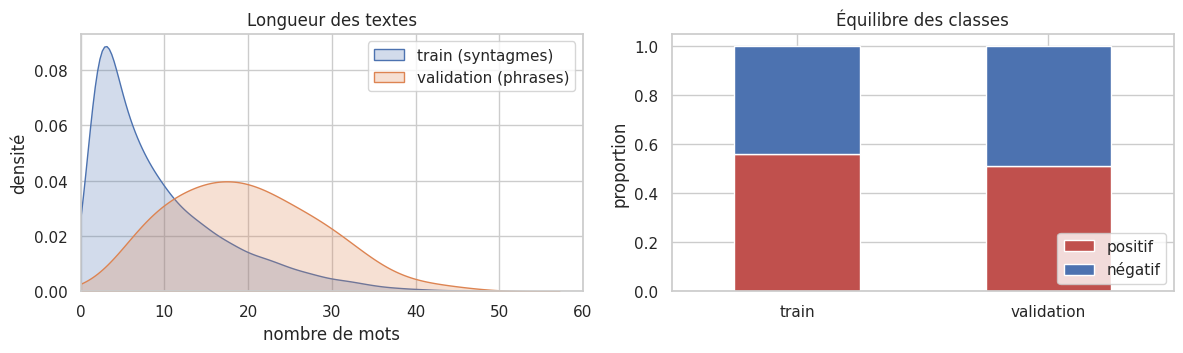

**Exemples (validation)**

,sentence,sentiment
794,it confirms fincher 's status as a film maker who artfully bends technical know-how to the service of psyc...,positif
319,too much of it feels unfocused and underdeveloped .,négatif
382,a great ensemble cast ca n't lift this heartfelt enterprise out of the familiar .,négatif
779,"prurient playthings aside , there 's little to love about this english trifle .",négatif
422,"it moves quickly , adroitly , and without fuss ; it does n't give you time to reflect on the inanity -- an...",positif


In [6]:
# ---------- 3.1 Composition des splits ----------
words = lambda s: s.str.split().str.len()
summary = pd.DataFrame({
    "split": ["train officiel (syntagmes)", "validation officielle (phrases)"],
    "n": [len(train_full), len(val_df)],
    "% positifs": [train_full.label.mean() * 100, val_df.label.mean() * 100],
    "mots / texte (moy.)": [words(train_full.sentence).mean(), words(val_df.sentence).mean()],
    "mots / texte (médiane)": [words(train_full.sentence).median(), words(val_df.sentence).median()]}).round(1)
display(summary.style.hide(axis="index").format({"n": "{:,}", "% positifs": "{:.1f}", "mots / texte (moy.)": "{:.1f}", "mots / texte (médiane)": "{:.1f}"}))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.7))
for name, d in [("train (syntagmes)", train_full), ("validation (phrases)", val_df)]:
    sns.kdeplot(words(d.sentence).clip(upper=60), ax=ax[0], label=name, fill=True, alpha=.25, bw_adjust=1.5, clip=(0, 60))
ax[0].set(title="Longueur des textes", xlabel="nombre de mots", ylabel="densité", xlim=(0, 60)); ax[0].legend()
bal = pd.DataFrame({"train": train_full.label.value_counts(normalize=True), "validation": val_df.label.value_counts(normalize=True)}).T.rename(columns={0: "négatif", 1: "positif"})
bal.plot.bar(stacked=True, ax=ax[1], color=["#c0504d", BLUE], rot=0); ax[1].set(title="Équilibre des classes", ylabel="proportion"); ax[1].legend(loc="lower right")
plt.tight_layout(); plt.savefig(OUT / "eda_overview.png", dpi=130); plt.show()
display(Markdown("**Exemples (validation)**")); display(val_df.sample(5, random_state=SEED).assign(sentiment=lambda d: d.label.map({0: "négatif", 1: "positif"}))[["sentence", "sentiment"]])

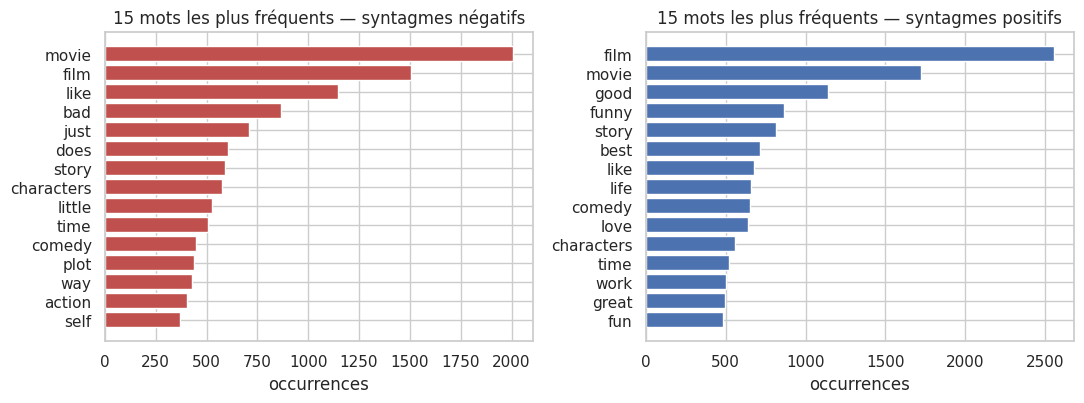

Mots communs aux deux listes de 15 : 7 (movie, film, like, story, characters, time, comedy) -> la fréquence brute discrimine peu le sentiment.


**Prévalence des marqueurs de négation et d'opposition** (mêmes motifs qu'en section 9)

,% avec négation,% avec opposition
train (syntagmes),10.3 %,5.1 %
validation (phrases),22.5 %,16.2 %
train · syntagmes négatifs,15.5 %,5.4 %
train · syntagmes positifs,6.1 %,4.9 %


Note : la liste de mots vides de scikit-learn contient des marqueurs de négation (cannot, neither, never, no, nobody, nor, not, nothing, without) : ils sont retirés de ce graphique, pas des modèles.


In [7]:
# ---------- 3.2 Vocabulaire par classe et marqueurs de négation / d'opposition ----------
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
cv = CountVectorizer(stop_words="english"); Xc = cv.fit_transform(train_full.sentence); vocab = np.array(cv.get_feature_names_out())
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2)); tops = {}
for k, (lab, name, col) in enumerate([(0, "négatifs", "#c0504d"), (1, "positifs", BLUE)]):
    cnt = np.asarray(Xc[train_full.label.values == lab].sum(0)).ravel(); idx = cnt.argsort()[::-1][:15]; tops[name] = list(vocab[idx])
    ax[k].barh(vocab[idx][::-1], cnt[idx][::-1], color=col); ax[k].set(title=f"15 mots les plus fréquents — syntagmes {name}", xlabel="occurrences")
plt.tight_layout(); plt.savefig(OUT / "eda_top_words.png", dpi=130); plt.show()
SHARED_TOP = [w for w in tops["négatifs"] if w in tops["positifs"]]
print(f"Mots communs aux deux listes de 15 : {len(SHARED_TOP)} ({', '.join(SHARED_TOP)}) -> la fréquence brute discrimine peu le sentiment.")

NEG = r"\b(?:not|no|never|nothing|neither|nor|without|hardly|barely|cannot|nobody)\b|n't"      # détection par mots-clés (approximative)
CON = r"\b(?:but|although|though|however|yet|despite)\b"
prev = pd.DataFrame({"% avec négation": [d.sentence.str.contains(NEG, regex=True).mean() * 100 for d in (train_full, val_df)],
                     "% avec opposition": [d.sentence.str.contains(CON, regex=True).mean() * 100 for d in (train_full, val_df)]},
                    index=["train (syntagmes)", "validation (phrases)"])
for lab, name in [(0, "négatifs"), (1, "positifs")]:
    prev.loc[f"train · syntagmes {name}"] = [train_full[train_full.label == lab].sentence.str.contains(p, regex=True).mean() * 100 for p in (NEG, CON)]
display(Markdown("**Prévalence des marqueurs de négation et d'opposition** (mêmes motifs qu'en section 9)")); display(prev.round(1).style.format("{:.1f} %"))
print("Note : la liste de mots vides de scikit-learn contient des marqueurs de négation "
      f"({', '.join(sorted(set(['not','no','never','nothing','neither','nor','without','hardly','barely','cannot','nobody']) & set(ENGLISH_STOP_WORDS)))}) : ils sont retirés de ce graphique, pas des modèles.")

In [8]:
# ---------- 3.3 Couverture du vocabulaire, doublons, étiquettes contradictoires, recouvrements ----------
tok = lambda s: [w for t in s.str.lower() for w in t.split()]
train_vocab = set(tok(train_full.sentence)); v_tok = tok(val_df.sentence); v_types = set(v_tok)
OOV_TYPES, OOV_TOK = np.mean([w not in train_vocab for w in v_types]) * 100, np.mean([w not in train_vocab for w in v_tok]) * 100

dup = int(train_full.sentence.duplicated().sum())
conf = train_full.groupby("sentence").label.nunique(); n_conflict = int((conf > 1).sum())
overlap_val = int(train_full.sentence.isin(set(val_df.sentence)).sum())
lens = pd.DataFrame({"train": words(train_full.sentence), "validation": words(val_df.sentence)}).describe(percentiles=[.5, .95, .99]).T[["mean", "50%", "95%", "99%", "max"]]
lens.columns = ["moyenne", "médiane", "95e centile", "99e centile", "maximum"]

display(Markdown(f"**Diagnostics de qualité du train officiel** — doublons exacts : **{dup}** · phrases à étiquette contradictoire : **{n_conflict}** · "
                 f"phrases du train identiques à une phrase de validation : **{overlap_val}** · vocabulaire du train : **{len(train_vocab):,}** mots distincts"))
display(Markdown(f"**Couverture du vocabulaire** — {OOV_TYPES:.1f} % des mots distincts de la validation ({OOV_TOK:.1f} % des occurrences) n'existent pas dans le train : "
                 "un modèle à vocabulaire fixe (TF-IDF) ne peut pas les exploiter, alors que la tokenisation en sous-mots de BERT les décompose."))
display(Markdown("**Longueur des textes (en mots)**")); display(lens.round(1).style.format("{:.1f}"))

**Diagnostics de qualité du train officiel** — doublons exacts : **371** · phrases à étiquette contradictoire : **5** · phrases du train identiques à une phrase de validation : **0** · vocabulaire du train : **14,816** mots distincts

**Couverture du vocabulaire** — 21.7 % des mots distincts de la validation (5.7 % des occurrences) n'existent pas dans le train : un modèle à vocabulaire fixe (TF-IDF) ne peut pas les exploiter, alors que la tokenisation en sous-mots de BERT les décompose.

**Longueur des textes (en mots)**

,moyenne,médiane,95e centile,99e centile,maximum
train,9.4,7.0,26.0,35.0,52.0
validation,19.5,19.0,34.4,42.0,47.0


**Lecture de l'exploration.** Ce que l'on peut affirmer *avant tout modèle* (les valeurs exactes sont affichées ci-dessus) :
* le train est constitué de **syntagmes courts** alors que la validation est faite de **phrases complètes** : il existe un décalage de distribution entre apprentissage et évaluation ;
* la fréquence brute des mots discrimine peu les classes (beaucoup de mots de contenu sont communs) ;
* les marqueurs de négation / d'opposition sont plus (ou moins) présents en validation qu'en train selon le tableau de prévalence : ce sont des constructions que les analyses de la section 9 isolent ;
* des **recouvrements exacts** entre train et validation, s'ils existent, seront retirés du train en section 4 pour éviter toute fuite.

## 4 · Prétraitement et découpage sans fuite
**Nettoyage minimal** (documenté et chiffré) : suppression des phrases à étiquette contradictoire, des doublons exacts et de toute phrase du train **identique à une phrase de la validation**. Le texte n'est pas retouché (GLUE est déjà normalisé) ; la normalisation propre à chaque modèle est faite par son tokenizer.

**Pourquoi un découpage par groupes ?** Le train SST-2 contient *toutes les sous-parties* de chaque phrase d'origine. Un tirage aléatoire de phrases mettrait par exemple « *a good movie* » dans `dev` et « *this is a good movie , but…* » dans `train_fit` : le `dev` serait alors **contaminé** et la sélection du meilleur modèle serait biaisée. On regroupe donc chaque syntagme avec la plus longue phrase du train qui le contient (comparaison de séquences contiguës de mots), puis on met de côté des **groupes entiers**. Le regroupement est approximatif pour les syntagmes très courts (un mot comme *good* apparaît dans de nombreuses phrases) ; on **mesure** la contamination résiduelle ci-dessous et on la compare à un tirage aléatoire.

In [9]:
# ---------- 4.1 Nettoyage ----------
def clean_train(df, forbidden):
    log = {"train officiel": len(df)}
    d = df.copy()
    c = d.groupby("sentence").label.nunique(); d = d[~d.sentence.isin(c[c > 1].index)];   log["− étiquettes contradictoires"] = len(d)
    d = d.drop_duplicates("sentence");                                                    log["− doublons exacts"] = len(d)
    d = d[~d.sentence.isin(forbidden)];                                                   log["− identiques à une phrase de validation"] = len(d)
    return d.reset_index(drop=True), log

train_clean, clean_log = clean_train(train_full, set(val_df.sentence))
steps = pd.DataFrame({"étape": list(clean_log), "textes restants": list(clean_log.values())})
steps["retirés"] = (-steps["textes restants"].diff()).fillna(0).astype(int)
display(steps.style.format({"textes restants": "{:,}", "retirés": "{:,}"}).hide(axis="index"))
assert not set(train_clean.sentence) & set(val_df.sentence)

étape,textes restants,retirés
train officiel,"67,349",0
− étiquettes contradictoires,"67,339",10
− doublons exacts,"66,973",366
− identiques à une phrase de validation,"66,973",0


In [10]:
# ---------- 4.2 Regroupement des syntagmes par phrase d'origine, puis découpage train_fit / dev ----------
def assign_groups(phrases):
    """Associe chaque syntagme au groupe de la plus longue phrase qui le contient (séquence contiguë de mots)."""
    order = sorted(range(len(phrases)), key=lambda i: (-len(phrases[i].split()), phrases[i]))
    span2group, groups, n_groups = {}, np.empty(len(phrases), dtype=np.int64), 0
    for i in order:
        g = span2group.get(phrases[i])
        if g is None:                                     # nouvelle « phrase maximale » : on indexe tous ses sous-segments
            g, n_groups = n_groups, n_groups + 1
            w = phrases[i].split(); n = len(w)
            for a in range(n):
                for b in range(a + 1, n + 1):
                    span2group.setdefault(" ".join(w[a:b]), g)
        groups[i] = g
    return groups, n_groups

phrases = train_clean.sentence.tolist()
groups, n_groups = assign_groups(phrases)
train_clean["group"] = groups
sizes = train_clean.group.value_counts()

rng = np.random.default_rng(SEED)
target, acc, dev_groups = int(DEV_FRACTION * len(train_clean)), 0, set()
for g in rng.permutation(sizes.index.values):
    if acc >= target: break
    dev_groups.add(int(g)); acc += int(sizes[g])
is_dev = train_clean.group.isin(dev_groups)
dev_df, train_fit = train_clean[is_dev].reset_index(drop=True), train_clean[~is_dev].reset_index(drop=True)
if MAX_TRAIN_SAMPLES:
    train_fit = train_fit.sample(min(MAX_TRAIN_SAMPLES, len(train_fit)), random_state=SEED).reset_index(drop=True)
    print(f"⚠️ Essai rapide : train_fit sous-échantillonné à {len(train_fit)} exemples (résultats non comparables au protocole complet).")

# ---- Mesure de la contamination : part des syntagmes de dev (≥ 5 mots) contenus dans une phrase du côté entraînement ----
def head_phrases(df):                                     # plus longue phrase de chaque groupe
    return df.assign(n=df.sentence.str.split().str.len()).sort_values(["group", "n"], ascending=[True, False]).drop_duplicates("group").sentence.tolist()
def contamination(dev_part, train_part):
    big = "\n".join(head_phrases(train_part)); cand = [p for p in dev_part.sentence if len(p.split()) >= 5]
    return np.mean([p in big for p in cand]) * 100, len(cand)
leak_grouped, n_eval = contamination(dev_df, train_clean[~is_dev])
rand_dev = train_clean.sample(len(dev_df), random_state=SEED); leak_random, _ = contamination(rand_dev, train_clean.drop(rand_dev.index))
LEAK = {"groupé": leak_grouped, "aléatoire": leak_random}
display(pd.DataFrame({"découpage": ["par groupes (utilisé)", "aléatoire (écarté)"], "syntagmes de dev (≥ 5 mots) contenus dans une phrase du train_fit (%)": [leak_grouped, leak_random]}).style.format({"syntagmes de dev (≥ 5 mots) contenus dans une phrase du train_fit (%)": "{:.1f}"}).hide(axis="index"))

découpage,syntagmes de dev (≥ 5 mots) contenus dans une phrase du train_fit (%)
par groupes (utilisé),0.0
aléatoire (écarté),84.0


In [11]:
# ---------- 4.3 Récapitulatif des jeux et de leur rôle ----------
roles = pd.DataFrame({
    "jeu": ["train_fit", "dev", "validation (officielle)", "test (officiel)"],
    "n": [len(train_fit), len(dev_df), len(val_df), N_TEST_HIDDEN],
    "% positifs": [train_fit.label.mean() * 100, dev_df.label.mean() * 100, val_df.label.mean() * 100, np.nan],
    "mots (moy.)": [words(train_fit.sentence).mean(), words(dev_df.sentence).mean(), words(val_df.sentence).mean(), np.nan],
    "rôle": ["apprentissage", "sélection (C, n-grammes, meilleure époque)", "évaluation finale (1 fois / modèle)", "étiquettes masquées : non utilisé"]}).round(1)
display(roles.style.hide(axis="index").format({"n": "{:,}", "% positifs": "{:.1f}", "mots (moy.)": "{:.1f}"}, na_rep="—"))
assert not set(train_fit.sentence) & set(dev_df.sentence) and not set(train_fit.sentence) & set(val_df.sentence) and not set(dev_df.sentence) & set(val_df.sentence)
assert not set(train_fit.group) & set(dev_df.group), "un groupe ne doit pas être partagé entre train_fit et dev"
print("✅ Les trois jeux sont disjoints (textes et groupes).")
display(Markdown(f"Contamination du `dev` : **{LEAK['groupé']:.1f} %** avec le découpage par groupes, contre **{LEAK['aléatoire']:.1f} %** pour un découpage aléatoire — "
                 "le découpage par groupes réduit nettement la fuite ; le résidu correspond à des coïncidences de séquences courtes."))

jeu,n,% positifs,mots (moy.),rôle
train_fit,"63,620",55.6,9.5,apprentissage
dev,"3,353",58.3,9.4,"sélection (C, n-grammes, meilleure époque)"
validation (officielle),872,50.9,19.5,évaluation finale (1 fois / modèle)
test (officiel),"1,821",—,—,étiquettes masquées : non utilisé


✅ Les trois jeux sont disjoints (textes et groupes).


Contamination du `dev` : **0.0 %** avec le découpage par groupes, contre **84.0 %** pour un découpage aléatoire — le découpage par groupes réduit nettement la fuite ; le résidu correspond à des coïncidences de séquences courtes.

In [12]:
# Chiffres déjà calculés en sections 3 et 4, enregistrés dans results/ pour que le rapport les cite
# sans recopie manuelle (aucun calcul nouveau, aucune décision prise ici). Convention : les clés « pct_ »
# sont en pourcentage (0 à 100) ; scripts/extraire_metriques.py les convertit en proportions « part_ ».
_etapes = list(clean_log.values())
DONNEES = {
    "train_officiel": len(train_full), "validation": len(val_df), "test_masque": int(N_TEST_HIDDEN),
    "doublons_exacts": int(dup), "phrases_contradictoires": int(n_conflict), "recouvrement_validation": int(overlap_val),
    "retires_contradictoires": _etapes[0] - _etapes[1], "retires_doublons": _etapes[1] - _etapes[2],
    "retires_recouvrement": _etapes[2] - _etapes[3], "train_nettoye": _etapes[3],
    "train_fit": len(train_fit), "dev": len(dev_df), "groupes_dev": len(dev_groups),
    "pct_positifs_train": float(train_full.label.mean() * 100), "pct_positifs_val": float(val_df.label.mean() * 100),
    "pct_positifs_train_fit": float(train_fit.label.mean() * 100), "pct_positifs_dev": float(dev_df.label.mean() * 100),
    "mots_moyens_train": float(words(train_full.sentence).mean()), "mots_moyens_val": float(words(val_df.sentence).mean()),
    "mots_medians_train": float(words(train_full.sentence).median()), "mots_medians_val": float(words(val_df.sentence).median()),
    "vocabulaire_train": len(train_vocab), "pct_types_val_hors_train": float(OOV_TYPES), "pct_occurrences_val_hors_train": float(OOV_TOK),
    "pct_contamination_groupes": float(LEAK["groupé"]), "pct_contamination_aleatoire": float(LEAK["aléatoire"]),
    "pct_negation_train": float(prev.iloc[0, 0]), "pct_negation_val": float(prev.iloc[1, 0]),
    "pct_opposition_train": float(prev.iloc[0, 1]), "pct_opposition_val": float(prev.iloc[1, 1]),
}
json.dump(DONNEES, open(OUT / "donnees_metrics.json", "w"), indent=2)

# Paramètres réellement utilisés par cette exécution (le bootstrap du rapport doit utiliser les mêmes)
PARAMS = {"seed": SEED, "n_boot": N_BOOT, "model_name": MODEL_NAME, "epochs": EPOCHS, "batch_size": BATCH_SIZE, "lr": LR,
          "weight_decay": WEIGHT_DECAY, "warmup_ratio": WARMUP_RATIO, "max_len": MAX_LEN, "grad_clip": GRAD_CLIP,
          "dev_fraction": DEV_FRACTION, "max_train_samples": MAX_TRAIN_SAMPLES, "run_extra_seeds": RUN_EXTRA_SEEDS,
          "extra_seeds": EXTRA_SEEDS, "run_frozen": RUN_FROZEN, "run_distilbert": RUN_DISTILBERT,
          "frozen_max_train": FROZEN_MAX_TRAIN, "frozen_c_grid": FROZEN_C_GRID, "distil_model_name": DISTIL_MODEL_NAME,
          "confident": CONFIDENT, "n_calib_bins": N_CALIB_BINS,
          "target_val_acc": TARGET_VAL_ACC, "device": device, "amp": str(amp_dtype).split(".")[-1] if use_amp else "aucune",
          "execution_complete": MODEL_NAME == "bert-base-uncased" and MAX_TRAIN_SAMPLES is None,
          "gpu": torch.cuda.get_device_name(0) if device == "cuda" else "aucun",
          "versions": {"python": platform.python_version(), **{m: ver(m) for m in ["torch", "transformers", "datasets", "sklearn", "scipy", "pandas", "numpy"]}}}
json.dump(PARAMS, open(OUT / "parametres_metrics.json", "w"), indent=2)
print(f"{len(DONNEES)} chiffres des sections 3-4 et {len(PARAMS)} paramètres enregistrés dans results/")

30 chiffres des sections 3-4 et 27 paramètres enregistrés dans results/


## 5 · Baseline : TF-IDF + régression logistique
Représentation TF-IDF (pondération sous-linéaire, fréquence minimale 2) suivie d'une régression logistique. **Les hyper-paramètres (n-grammes, `C`) sont choisis sur `dev`** ; la validation officielle n'est évaluée qu'**une fois**, avec le modèle retenu.

In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score, roc_auc_score, matthews_corrcoef,
                             confusion_matrix, roc_curve, classification_report)

def compute_metrics(y, proba, thr=0.5):
    y = np.asarray(y); pred = (np.asarray(proba) >= thr).astype(int)
    p, r, f, _ = precision_recall_fscore_support(y, pred, average="binary", zero_division=0)
    return dict(accuracy=accuracy_score(y, pred), precision=p, recall=r, f1=f, macro_f1=f1_score(y, pred, average="macro"),
                mcc=matthews_corrcoef(y, pred), roc_auc=roc_auc_score(y, proba))

def save_preds(name, split, df, proba):
    out = df[["idx", "sentence", "label"]].copy(); out["proba"] = np.asarray(proba); out["pred"] = (out.proba >= 0.5).astype(int)
    out.to_csv(OUT / f"{name}_{split}_preds.csv", index=False)

FINAL_EVAL = {}                                                   # garde-fou : la validation officielle ne sert qu'à l'évaluation finale
def evaluate_final(name, proba):
    if name in FINAL_EVAL:
        print(f"⚠️ Validation officielle déjà évaluée pour '{name}' : ne pas relancer pour ajuster des choix (sélection uniquement sur dev).")
    FINAL_EVAL[name] = FINAL_EVAL.get(name, 0) + 1
    save_preds(name, "val", val_df, proba); return compute_metrics(val_df.label, proba)

# ---- Recherche d'hyper-paramètres sur dev uniquement ----
t0, rows = time.time(), []
for ngram in [(1, 1), (1, 2)]:
    vec = TfidfVectorizer(ngram_range=ngram, sublinear_tf=True, min_df=2)
    Xtr, Xdev = vec.fit_transform(train_fit.sentence), vec.transform(dev_df.sentence)
    for C in [0.3, 1, 3, 10, 30]:
        clf = LogisticRegression(C=C, max_iter=2000).fit(Xtr, train_fit.label)
        rows.append(dict(ngram=ngram, C=C, dev_acc=accuracy_score(dev_df.label, clf.predict(Xdev))))
grid = pd.DataFrame(rows).sort_values(["dev_acc", "C"], ascending=[False, True]).reset_index(drop=True)
display(grid.head(10).style.format({"dev_acc": "{:.4f}", "C": "{:g}"}).hide(axis="index"))
best = grid.iloc[0]; print(f"Configuration retenue sur dev : ngram={best.ngram}, C={best.C}  ({time.time()-t0:.0f} s)")

ngram,C,dev_acc
"(1, 2)",30,0.8097
"(1, 2)",10,0.8058
"(1, 2)",3,0.8023
"(1, 1)",3,0.7939
"(1, 2)",1,0.7936
"(1, 1)",1,0.7930
"(1, 1)",10,0.7930
"(1, 1)",30,0.7924
"(1, 1)",0.3,0.7894
"(1, 2)",0.3,0.7784


Configuration retenue sur dev : ngram=(1, 2), C=30.0  (44 s)


In [14]:
# ---- Modèle final de la baseline (entraîné sur train_fit) ----
vec = TfidfVectorizer(ngram_range=best.ngram, sublinear_tf=True, min_df=2)
Xtr = vec.fit_transform(train_fit.sentence)
clf = LogisticRegression(C=best.C, max_iter=2000).fit(Xtr, train_fit.label)
p_dev = clf.predict_proba(vec.transform(dev_df.sentence))[:, 1]; p_val = clf.predict_proba(vec.transform(val_df.sentence))[:, 1]
base_metrics = {"dev": compute_metrics(dev_df.label, p_dev), "val": evaluate_final("tfidf", p_val)}
save_preds("tfidf", "dev", dev_df, p_dev)
json.dump({"model": "TF-IDF + LogReg", "ngram": list(best.ngram), "C": float(best.C), "n_features": int(Xtr.shape[1]), "n_train": len(train_fit), **base_metrics},
          open(OUT / "tfidf_metrics.json", "w"), indent=2)
display(pd.DataFrame(base_metrics).T.rename(index={"dev": "dev (sélection)", "val": "validation officielle"}).round(4))

coef = pd.Series(clf.coef_[0], index=vec.get_feature_names_out()).sort_values()
display(pd.DataFrame({"plus négatifs": coef.index[:10].tolist(), "poids": coef.values[:10].round(2),
                      "plus positifs": coef.index[::-1][:10].tolist(), "poids ": coef.values[::-1][:10].round(2)}))

,accuracy,precision,recall,f1,macro_f1,mcc,roc_auc
dev (sélection),0.8097,0.8198,0.8634,0.8411,0.8020,0.6057,0.8854
validation officielle,0.8188,0.7930,0.8716,0.8305,0.8179,0.6401,0.9122


,plus négatifs,poids,plus positifs,poids
0,lacks,-16.17,not bad,15.95
1,worst,-14.85,not too,15.81
2,lacking,-14.40,never dull,14.65
3,bad,-13.86,fascinating,14.10
4,too,-13.42,powerful,13.49
5,mess,-13.34,beautiful,13.07
6,stupid,-12.62,good,13.01
7,failure,-11.62,remarkable,12.87
8,neither,-11.56,hilarious,12.84
9,not,-11.28,best,12.71


**Interprétation de la baseline.** Les poids les plus extrêmes montrent ce qu'un modèle « sac de n-grammes » peut apprendre : des mots ou des bigrammes fortement polarisés. Si des **bigrammes de négation** (*not bad*, *never dull*…) figurent parmi les poids élevés, c'est de la **mémorisation de combinaisons vues à l'entraînement**, non une règle générale « négation ⇒ inversion » : c'est une observation sur les coefficients, que la section 9 confronte aux erreurs.

## 6 · Architecture BERT et stratégie de fine-tuning
**Architecture.** `bert-base-uncased` : encodeur Transformer à **12 couches**, 768 dimensions cachées, 12 têtes d'attention, ≈ 110 M de paramètres, pré-entraîné (prédiction de mots masqués + phrase suivante). Pour la classification, `AutoModelForSequenceClassification` ajoute au-dessus de la représentation du jeton `[CLS]` un *dropout* puis une **couche linéaire à 2 sorties**.

> Au chargement, Hugging Face affiche un rapport signalant des poids `UNEXPECTED` (têtes de pré-entraînement, ignorées) et `MISSING` (la nouvelle couche de classification, initialisée aléatoirement). C'est **normal** : cette couche est apprise pendant le fine-tuning.

**Stratégie d'entraînement.**

| Élément | Choix | Justification |
|---|---|---|
| Optimiseur | AdamW, `lr = 2e-5`, `weight_decay = 0.01` (hors biais et LayerNorm) | valeurs usuelles du fine-tuning de BERT ; la régularisation ne s'applique pas aux biais |
| Scheduler | warm-up linéaire (10 % des pas) puis décroissance linéaire | stabilise les premiers pas sur un modèle pré-entraîné |
| Gradient clipping | norme ≤ 1,0 | limite les gradients explosifs |
| Précision mixte | fp16 (T4) ou bf16 (Ampere+), `GradScaler` en fp16 | vitesse et mémoire ; perte calculée en pleine précision |
| Batch / époques / longueur | 32 / 3 / `max_len = 128` (rembourrage dynamique) | vérifié ci-dessous sur la distribution réelle des longueurs |
| Sélection | meilleure accuracy sur **`dev`** à chaque époque (égalité : plus faible loss) | aucune décision n'est prise sur la validation officielle |
| `train()` / `eval()` / `no_grad` | `model.train()` pendant l'entraînement (dropout actif) ; `model.eval()` + `torch.no_grad()` à l'évaluation | comportement correct du dropout, pas de graphe de calcul inutile |

In [15]:
BERT_AVAILABLE, BERT_ERROR = False, None
if RUN_BERT:
    try:
        from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
        tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
        _probe = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)
        BERT_AVAILABLE = True
        cfg = _probe.config
        display(pd.DataFrame({"paramètre": ["modèle", "couches", "dimension cachée", "têtes d'attention", "paramètres (M)", "tête de classification"],
                              "valeur": [MODEL_NAME, getattr(cfg, "num_hidden_layers", getattr(cfg, "n_layers", "?")), getattr(cfg, "hidden_size", getattr(cfg, "dim", "?")),
                                         getattr(cfg, "num_attention_heads", getattr(cfg, "n_heads", "?")), f"{sum(p.numel() for p in _probe.parameters())/1e6:.0f}", str(_probe.classifier)]}).style.hide(axis="index"))
        del _probe; gc.collect()

        # ---- Vérification de la tokenisation, du rembourrage et du masque d'attention ----
        ex = tokenizer(["this film is n't bad at all ."], return_tensors="pt")
        print("Exemple :", tokenizer.convert_ids_to_tokens(ex["input_ids"][0]))
        batch = tokenizer(train_fit.sentence.iloc[:4].tolist(), padding=True, truncation=True, max_length=MAX_LEN, return_tensors="pt")
        assert batch["attention_mask"].shape == batch["input_ids"].shape
        print("Batch de contrôle :", {k: tuple(v.shape) for k, v in batch.items()}, "| jetons non masqués par texte :", batch["attention_mask"].sum(1).tolist())

        # ---- Longueurs réelles en jetons vs max_len ----
        samp = train_fit.sentence.sample(min(10_000, len(train_fit)), random_state=SEED).tolist() + val_df.sentence.tolist()
        tl = pd.Series([len(x) for x in tokenizer(samp, add_special_tokens=True, truncation=False)["input_ids"]])
        TOK = dict(p95=tl.quantile(.95), p99=tl.quantile(.99), max=int(tl.max()), trunc=(tl > MAX_LEN).mean() * 100)
        display(Markdown(f"**Longueur en jetons** : 95e centile = {TOK['p95']:.0f} · 99e centile = {TOK['p99']:.0f} · maximum = {TOK['max']} · "
                         f"**{TOK['trunc']:.2f} %** des textes dépassent `max_len = {MAX_LEN}` (tronqués)."))
    except Exception as e:
        BERT_ERROR = f"{type(e).__name__}: {str(e)[:300]}"
        print("❌ Impossible de charger le modèle/tokenizer — l'entraînement BERT sera ignoré. Cause :", BERT_ERROR)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


paramètre,valeur
modèle,bert-base-uncased
couches,12
dimension cachée,768
têtes d'attention,12
paramètres (M),109
tête de classification,"Linear(in_features=768, out_features=2, bias=True)"


Exemple : ['[CLS]', 'this', 'film', 'is', 'n', "'", 't', 'bad', 'at', 'all', '.', '[SEP]']
Batch de contrôle : {'input_ids': (4, 15), 'token_type_ids': (4, 15), 'attention_mask': (4, 15)} | jetons non masqués par texte : [10, 11, 15, 10]


**Longueur en jetons** : 95e centile = 35 · 99e centile = 46 · maximum = 62 · **0.00 %** des textes dépassent `max_len = 128` (tronqués).

### 6.1 · Ce que voit BERT : WordPiece, `[CLS]`, `[SEP]` et rembourrage
BERT ne lit pas des mots mais des unités WordPiece, tirées d'un vocabulaire de 30 522 entrées pour `bert-base-uncased`. Un mot fréquent reste entier. Un mot rare est découpé en morceaux connus, et le préfixe `##` signale la suite d'un mot : un mot n'est donc presque jamais inconnu du modèle (le nombre de `[UNK]` est compté plus bas), alors que TF-IDF ignore tout mot absent de son vocabulaire. Le tokenizer ajoute `[CLS]` en tête, dont le vecteur final sert à la classification, et `[SEP]` en fin de phrase. Dans un lot, les phrases courtes sont complétées par `[PAD]` et le masque d'attention vaut 0 sur ces positions pour que l'attention les ignore.

In [16]:
if BERT_AVAILABLE:
    # ---- 6.1.a Découpage de quelques phrases ----
    phrases_demo = ["this film is n't bad at all .",
                    "an unflinchingly bleak and desperate vision .",
                    "the screenplay is self-congratulatory and overwrought .",
                    "embeddings"]
    display(pd.DataFrame([{"texte": s, "unités WordPiece": " ".join(tokenizer.tokenize(s)),
                           "mots": len(s.split()), "unités": len(tokenizer.tokenize(s))} for s in phrases_demo])
            .style.hide(axis="index"))

    # ---- 6.1.b Un lot de deux phrases : jetons spéciaux, rembourrage, masque d'attention ----
    lot = tokenizer(["a gorgeous film .", "the plot is thin , but the actors save it ."], padding=True, return_tensors="pt")
    toks = [tokenizer.convert_ids_to_tokens(ids) for ids in lot["input_ids"]]
    display(pd.DataFrame({"phrase 1": toks[0], "masque 1": lot["attention_mask"][0].tolist(),
                          "phrase 2": toks[1], "masque 2": lot["attention_mask"][1].tolist()}).T)

    # ---- 6.1.c Mesures sur la validation officielle ----
    mots_val = sorted({w for s in val_df.sentence for w in s.split()})
    n_unites = {w: len(tokenizer.tokenize(w)) for w in mots_val}
    hors_train = [w for w in mots_val if w.lower() not in train_vocab]
    ids_val = tokenizer(val_df.sentence.tolist(), add_special_tokens=False)["input_ids"]
    n_jetons = sum(len(seq) for seq in ids_val)
    TOKSTAT = {
        "mots_distincts_val": len(mots_val),
        "pct_mots_fragmentes": float(np.mean([n > 1 for n in n_unites.values()]) * 100),
        "mots_hors_train": len(hors_train),
        "pct_hors_train_fragmentes": float(np.mean([n_unites[w] > 1 for w in hors_train]) * 100) if hors_train else float("nan"),
        "jetons_inconnus_val": int(sum(i == tokenizer.unk_token_id for seq in ids_val for i in seq)),
        "unites_par_mot": n_jetons / sum(len(s.split()) for s in val_df.sentence),
        "p95_jetons": float(TOK["p95"]), "p99_jetons": float(TOK["p99"]), "max_jetons": int(TOK["max"]),
        "pct_tronques": float(TOK["trunc"]),
    }
    json.dump(TOKSTAT, open(OUT / "tokenisation_metrics.json", "w"), indent=2)
    exemples_rares = sorted(hors_train, key=lambda w: (-n_unites[w], w))[:8]
    display(pd.DataFrame({"mot absent du train": exemples_rares,
                          "unités WordPiece": [" ".join(tokenizer.tokenize(w)) for w in exemples_rares]}).style.hide(axis="index"))
    display(Markdown(
        f"Sur les {TOKSTAT['mots_distincts_val']} mots distincts de la validation, {fr(TOKSTAT['pct_mots_fragmentes'])} % sont "
        f"découpés en plusieurs unités ; c'est le cas de {fr(TOKSTAT['pct_hors_train_fragmentes'])} % des "
        f"{TOKSTAT['mots_hors_train']} mots absents du train. La validation compte {TOKSTAT['jetons_inconnus_val']} jeton(s) "
        f"`[UNK]` et {fr(TOKSTAT['unites_par_mot'], 2)} unités par mot en moyenne. Le texte le plus long mesuré en "
        f"section 6 fait {TOKSTAT['max_jetons']} jetons, donc `max_len = {MAX_LEN}` ne tronque "
        f"{'rien' if TOKSTAT['pct_tronques'] == 0 else fr(TOKSTAT['pct_tronques'], 2) + ' % des textes'} ; la valeur de 64 "
        f"proposée dans le cours {'suffirait aussi' if TOKSTAT['max_jetons'] <= 64 else 'tronquerait quelques textes'}."))

texte,unités WordPiece,mots,unités
this film is n't bad at all .,this film is n ' t bad at all .,8,10
an unflinchingly bleak and desperate vision .,an un ##fl ##in ##ching ##ly bleak and desperate vision .,7,11
the screenplay is self-congratulatory and overwrought .,the screenplay is self - cong ##rat ##ulator ##y and over ##wr ##ough ##t .,7,15
embeddings,em ##bed ##ding ##s,1,4


,0,1,2,3,4,5,6,7,8,9,10,11,12
phrase 1,[CLS],a,gorgeous,film,.,[SEP],[PAD],[PAD],[PAD],[PAD],[PAD],[PAD],[PAD]
masque 1,1,1,1,1,1,1,0,0,0,0,0,0,0
phrase 2,[CLS],the,plot,is,thin,",",but,the,actors,save,it,.,[SEP]
masque 2,1,1,1,1,1,1,1,1,1,1,1,1,1


mot absent du train,unités WordPiece
fly-on-the-wall,fly - on - the - wall
ooky-spookies,o ##ok ##y - sp ##ook ##ies
romijn-stamos,rom ##ij ##n - st ##amo ##s
inconsequentiality,inc ##ons ##e ##quent ##ial ##ity
socio-histo-political,socio - his ##to - political
all-in-all,all - in - all
bait-and-tackle,bait - and - tackle
blue-light-special,blue - light - special


Sur les 4339 mots distincts de la validation, 30,2 % sont découpés en plusieurs unités ; c'est le cas de 61,7 % des 940 mots absents du train. La validation compte 0 jeton(s) `[UNK]` et 1,18 unités par mot en moyenne. Le texte le plus long mesuré en section 6 fait 62 jetons, donc `max_len = 128` ne tronque rien ; la valeur de 64 proposée dans le cours suffirait aussi.

## 7 · Entraînement et validation
La boucle est **explicite** (pas de `Trainer`) : elle reste lisible et indépendante des versions de `transformers`. Les graines sont refixées avant la création du modèle, ce qui rend l'initialisation de la tête de classification reproductible. Le meilleur *checkpoint* (selon `dev`) est **écrit sur disque** à chaque amélioration, puis rechargé en fin d'entraînement.

In [17]:
def make_loader(df, bs, shuffle, seed=SEED):
    texts, labels = df.sentence.tolist(), df.label.tolist()
    def collate(ids):
        enc = tokenizer([texts[i] for i in ids], truncation=True, max_length=MAX_LEN, padding=True, return_tensors="pt")   # padding dynamique + attention_mask
        enc["labels"] = torch.tensor([labels[i] for i in ids], dtype=torch.long)
        return enc
    g = torch.Generator(); g.manual_seed(seed)
    return torch.utils.data.DataLoader(list(range(len(df))), batch_size=bs, shuffle=shuffle, collate_fn=collate, generator=g)

def autocast_ctx():
    return torch.autocast(device_type="cuda", dtype=amp_dtype, enabled=use_amp)

@torch.no_grad()
def evaluate(model, df, bs=EVAL_BATCH):
    model.eval(); probs, total = [], 0.0
    for batch in make_loader(df, bs, shuffle=False):
        batch = {k: v.to(device) for k, v in batch.items()}
        with autocast_ctx(): out = model(**batch)
        total += out.loss.item() * len(batch["labels"]); probs.append(torch.softmax(out.logits.float(), -1)[:, 1].cpu().numpy())
    return total / len(df), np.concatenate(probs)

def fine_tune(seed=SEED, tag="main"):
    """Fine-tuning complet ; retourne (modèle chargé avec le meilleur checkpoint selon dev, historique, durée en s)."""
    from tqdm.auto import tqdm
    set_seed(seed)                                                              # graine avant la création de la tête de classification
    model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2).to(device)
    loader = make_loader(train_fit, BATCH_SIZE, shuffle=True, seed=seed)
    total_steps = EPOCHS * len(loader)
    no_decay = ("bias", "LayerNorm.weight", "layer_norm", "LayerNorm.bias")
    groups_ = [{"params": [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)], "weight_decay": WEIGHT_DECAY},
               {"params": [p for n, p in model.named_parameters() if any(nd in n for nd in no_decay)], "weight_decay": 0.0}]
    opt = torch.optim.AdamW(groups_, lr=LR)
    sched = get_linear_schedule_with_warmup(opt, int(WARMUP_RATIO * total_steps), total_steps)
    scaler = torch.amp.GradScaler("cuda", enabled=use_scaler)
    ckpt = CKPT_DIR / f"best_{tag}.pt"
    history, best = [], (-1.0, float("inf")); t0 = time.time()
    for epoch in range(1, EPOCHS + 1):
        model.train(); run, n, step = 0.0, 0, 0                                  # dropout actif
        bar = tqdm(loader, desc=f"[{tag}] époque {epoch}/{EPOCHS}", leave=False, mininterval=15)
        for batch in bar:
            batch = {k: v.to(device) for k, v in batch.items()}
            opt.zero_grad(set_to_none=True)
            with autocast_ctx(): loss = model(**batch).loss                      # input_ids + attention_mask (+ token_type_ids) + labels
            scaler.scale(loss).backward()
            scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            scaler.step(opt); scaler.update(); sched.step()
            run += loss.item() * len(batch["labels"]); n += len(batch["labels"]); step += 1
            if step % 100 == 0: bar.set_postfix(loss=f"{run/n:.4f}")
        dev_loss, dp = evaluate(model, dev_df)                                   # SÉLECTION sur dev, jamais sur la validation officielle
        dev_acc = accuracy_score(dev_df.label, dp >= 0.5)
        history.append(dict(epoch=epoch, train_loss=run / n, dev_loss=dev_loss, dev_acc=dev_acc, elapsed_min=(time.time() - t0) / 60))
        print(f"[{tag}] époque {epoch}: train_loss={run/n:.4f} | dev_loss={dev_loss:.4f} | dev_acc={dev_acc:.4f} | {history[-1]['elapsed_min']:.1f} min")
        if dev_acc > best[0] or (dev_acc == best[0] and dev_loss < best[1]):
            best = (dev_acc, dev_loss); torch.save(model.state_dict(), ckpt)      # sauvegarde du meilleur checkpoint
    model.load_state_dict(torch.load(ckpt, map_location=device))
    del opt, sched, scaler; gc.collect(); torch.cuda.empty_cache()
    return model, history, time.time() - t0

def free_gpu(*objs):
    for o in objs: del o
    gc.collect(); torch.cuda.empty_cache()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[main] époque 1/3:   0%|          | 0/1989 [00:00<?, ?it/s]

[main] époque 1: train_loss=0.2525 | dev_loss=0.2586 | dev_acc=0.9102 | 3.8 min


[main] époque 2/3:   0%|          | 0/1989 [00:00<?, ?it/s]

[main] époque 2: train_loss=0.1149 | dev_loss=0.2525 | dev_acc=0.9201 | 7.3 min


[main] époque 3/3:   0%|          | 0/1989 [00:00<?, ?it/s]

[main] époque 3: train_loss=0.0724 | dev_loss=0.2850 | dev_acc=0.9198 | 10.8 min


,accuracy,precision,recall,f1,macro_f1,mcc,roc_auc
dev (sélection),0.9201,0.9237,0.9407,0.9321,0.9175,0.8352,0.9744
validation officielle,0.9266,0.9204,0.9369,0.9286,0.9265,0.8533,0.9755


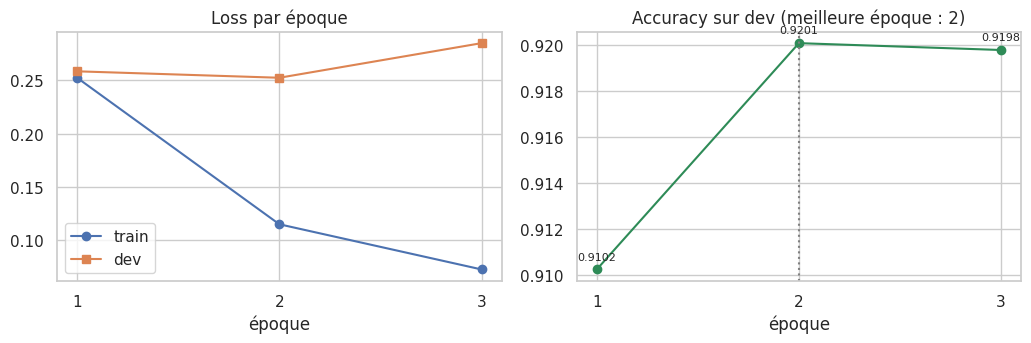

In [18]:
if BERT_AVAILABLE:
    model, history, train_seconds = fine_tune(SEED, tag="main")
    hist = pd.DataFrame(history); best_epoch = int(hist.dev_acc.idxmax() + 1)
    _, p_dev = evaluate(model, dev_df); _, p_val = evaluate(model, val_df)
    bert_metrics = {"dev": compute_metrics(dev_df.label, p_dev), "val": evaluate_final("bert", p_val)}      # validation officielle : évaluée UNE fois
    save_preds("bert", "dev", dev_df, p_dev); hist.to_csv(OUT / "bert_history.csv", index=False)
    json.dump({"model": MODEL_NAME, "epochs": EPOCHS, "batch_size": BATCH_SIZE, "lr": LR, "max_len": MAX_LEN, "device": device, "amp": str(amp_dtype).split(".")[-1] if use_amp else "none",
               "seed": SEED, "n_train": len(train_fit), "train_minutes": train_seconds / 60, "best_epoch": best_epoch, **bert_metrics}, open(OUT / "bert_metrics.json", "w"), indent=2)
    if SAVE_MODEL:
        model.save_pretrained(OUT / "bert_sst2_model"); tokenizer.save_pretrained(OUT / "bert_sst2_model")
    display(pd.DataFrame(bert_metrics).T.rename(index={"dev": "dev (sélection)", "val": "validation officielle"}).round(4))

    fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.6))
    ax[0].plot(hist.epoch, hist.train_loss, "o-", color=BLUE, label="train"); ax[0].plot(hist.epoch, hist.dev_loss, "s-", color=ORANGE, label="dev")
    ax[0].set(title="Loss par époque", xlabel="époque", xticks=hist.epoch); ax[0].legend()
    ax[1].plot(hist.epoch, hist.dev_acc, "o-", color="#2e8b57"); ax[1].axvline(best_epoch, ls=":", c="grey"); ax[1].set(title=f"Accuracy sur dev (meilleure époque : {best_epoch})", xlabel="époque", xticks=hist.epoch)
    for e, a in zip(hist.epoch, hist.dev_acc): ax[1].annotate(f"{a:.4f}", (e, a), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
    plt.tight_layout(); plt.savefig(OUT / "bert_learning_curves.png", dpi=130); plt.show()
    del model; free_gpu()
else:
    print("⏭️  Entraînement BERT ignoré (voir la cellule de chargement). Les sections 8 à 10 s'exécutent avec la baseline seule.")

**Lecture des courbes.** On compare la *loss d'entraînement* et la *loss de `dev`* : un écart qui se creuse (train qui baisse, `dev` qui remonte) indique du **surapprentissage**, ce qui justifie la sélection du checkpoint sur `dev` plutôt que de prendre la dernière époque. La courbe de `dev` porte sur des **syntagmes** (comme le train) ; elle sert à choisir l'époque, pas à estimer la performance sur des phrases complètes — c'est le rôle de la validation officielle (section 8).

In [19]:
# ---------- (Optionnel) variabilité due à la graine : RUN_EXTRA_SEEDS = True ----------
if BERT_AVAILABLE and RUN_EXTRA_SEEDS:
    seed_rows = [{"graine": SEED, "dev_acc": bert_metrics["dev"]["accuracy"], "val_acc": bert_metrics["val"]["accuracy"]}]
    for s in EXTRA_SEEDS:
        m, h, _ = fine_tune(s, tag=f"seed{s}")
        _, pd_ = evaluate(m, dev_df); _, pv_ = evaluate(m, val_df)
        seed_rows.append({"graine": s, "dev_acc": accuracy_score(dev_df.label, pd_ >= 0.5), "val_acc": evaluate_final(f"bert_seed{s}", pv_)["accuracy"]})
        del m; free_gpu()
    sd = pd.DataFrame(seed_rows); display(sd.style.format({"dev_acc": "{:.4f}", "val_acc": "{:.4f}"}).hide(axis="index"))
    display(Markdown(f"**Accuracy de validation sur {len(sd)} graines : {sd.val_acc.mean():.4f} ± {sd.val_acc.std(ddof=1):.4f}** (moyenne ± écart-type)."))
    sd.to_csv(OUT / "bert_seeds.csv", index=False)
else:
    print("Variabilité inter-graines non calculée (RUN_EXTRA_SEEDS = False) : les conclusions reposent sur UNE graine.")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[seed43] époque 1/3:   0%|          | 0/1989 [00:00<?, ?it/s]

[seed43] époque 1: train_loss=0.2576 | dev_loss=0.2372 | dev_acc=0.9102 | 3.5 min


[seed43] époque 2/3:   0%|          | 0/1989 [00:00<?, ?it/s]

[seed43] époque 2: train_loss=0.1184 | dev_loss=0.2461 | dev_acc=0.9225 | 7.1 min


... (8 outputs left out)

[seed44] époque 3/3:   0%|          | 0/1989 [00:00<?, ?it/s]

[seed44] époque 3: train_loss=0.0712 | dev_loss=0.2814 | dev_acc=0.9219 | 10.6 min


graine,dev_acc,val_acc
42,0.9201,0.9266
43,0.9225,0.9243
44,0.9260,0.9312


**Accuracy de validation sur 3 graines : 0.9274 ± 0.0035** (moyenne ± écart-type).

### 7.1 · Bonus du cours : BERT gelé contre fine-tuning complet
Le cours propose de comparer le fine-tuning complet, où les 110 M de poids sont ajustés, à une version où BERT reste gelé et où seule une couche de classification est apprise. On procède en deux temps. Le BERT pré-entraîné, sans aucune adaptation, encode chaque phrase ; une régression logistique est ensuite entraînée sur ces vecteurs, ce qui se rapproche de n'entraîner que la tête de classification. Deux représentations sont testées : le vecteur de sortie du jeton `[CLS]`, point de départ de la tête de classification de BERT (qui lui applique encore une couche dense pré-entraînée, le *pooler*), et la moyenne des vecteurs de tous les jetons. Le paramètre `C` est choisi sur `dev` et la validation officielle n'est évaluée qu'une fois par variante.

In [20]:
from sklearn.preprocessing import StandardScaler

def load_best_bert(tag="main"):
    """Recharge le meilleur checkpoint du fine-tuning (choisi sur dev), en mode évaluation."""
    with silence_hf():
        m = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2).to(device)
    m.load_state_dict(torch.load(CKPT_DIR / f"best_{tag}.pt", map_location=device))
    return m.eval()

FROZEN_RESULTS = {}
if BERT_AVAILABLE and RUN_FROZEN:
    from transformers import AutoModel
    t_cellule = time.time()
    set_seed()
    with silence_hf():
        encoder = AutoModel.from_pretrained(MODEL_NAME).to(device).eval()  # poids pré-entraînés, aucun fine-tuning

    @torch.no_grad()
    def encode(texts, bs=EVAL_BATCH):
        """Vecteur [CLS] et moyenne des jetons non masqués, en sortie de la dernière couche."""
        cls_, mean_ = [], []
        for i in range(0, len(texts), bs):
            b = tokenizer(texts[i:i + bs], truncation=True, max_length=MAX_LEN, padding=True, return_tensors="pt").to(device)
            with autocast_ctx():
                h = encoder(**b).last_hidden_state.float()
            mask = b["attention_mask"].unsqueeze(-1).float()
            cls_.append(h[:, 0].cpu().numpy())
            mean_.append(((h * mask).sum(1) / mask.sum(1)).cpu().numpy())
        return np.concatenate(cls_), np.concatenate(mean_)

    fit_df = train_fit if FROZEN_MAX_TRAIN is None else train_fit.sample(min(FROZEN_MAX_TRAIN, len(train_fit)), random_state=SEED)
    t0 = time.time()
    EMB = {name: encode(df.sentence.tolist()) for name, df in [("train", fit_df), ("dev", dev_df), ("val", val_df)]}
    embed_min = (time.time() - t0) / 60
    for k, rep in enumerate(["cls", "mean"]):
        key = f"frozen_{rep}"
        sc = StandardScaler().fit(EMB["train"][k])
        Xtr_, Xdev_, Xval_ = (sc.transform(EMB[s][k]) for s in ("train", "dev", "val"))
        grid_rows = []
        for C_ in FROZEN_C_GRID:                                                # sélection de C sur dev uniquement
            lr_ = LogisticRegression(C=C_, max_iter=5000).fit(Xtr_, fit_df.label)
            grid_rows.append({"C": C_, "dev_acc": accuracy_score(dev_df.label, lr_.predict(Xdev_))})
        best_C = float(pd.DataFrame(grid_rows).sort_values(["dev_acc", "C"], ascending=[False, True]).iloc[0].C)
        lr_ = LogisticRegression(C=best_C, max_iter=5000).fit(Xtr_, fit_df.label)
        p_dev_, p_val_ = lr_.predict_proba(Xdev_)[:, 1], lr_.predict_proba(Xval_)[:, 1]
        FROZEN_RESULTS[key] = {"dev": compute_metrics(dev_df.label, p_dev_), "val": evaluate_final(key, p_val_)}
        save_preds(key, "dev", dev_df, p_dev_)
        json.dump({"model": f"{MODEL_NAME} gelé ({'[CLS]' if rep == 'cls' else 'moyenne des jetons'}) + LogReg",
                   "representation": rep, "C": best_C, "n_train": len(fit_df), "embed_minutes": embed_min,
                   "grid": grid_rows, **FROZEN_RESULTS[key]}, open(OUT / f"{key}_metrics.json", "w"), indent=2)
    del encoder, EMB, Xtr_, Xdev_, Xval_
    free_gpu()
    total_min = (time.time() - t_cellule) / 60                                 # encodage + toutes les régressions
    for key in FROZEN_RESULTS:
        f_ = OUT / f"{key}_metrics.json"; d_ = json.load(open(f_)); d_["total_minutes"] = total_min
        json.dump(d_, open(f_, "w"), indent=2)

    lignes = [("TF-IDF + LogReg", base_metrics), ("BERT gelé, [CLS] + LogReg", FROZEN_RESULTS["frozen_cls"]),
              ("BERT gelé, moyenne + LogReg", FROZEN_RESULTS["frozen_mean"]), ("BERT fine-tuné", bert_metrics)]
    cols_acc = ["accuracy dev", "accuracy validation", "F1 validation", "ROC-AUC validation"]
    display(pd.DataFrame([{"modèle": n, "accuracy dev": r["dev"]["accuracy"], "accuracy validation": r["val"]["accuracy"],
                           "F1 validation": r["val"]["f1"], "ROC-AUC validation": r["val"]["roc_auc"]} for n, r in lignes])
            .style.format({c: "{:.4f}" for c in cols_acc}).hide(axis="index"))
    print(f"Encodage des trois jeux par le BERT gelé : {embed_min:.1f} min sur {device.upper()} ; "
          f"cellule complète, régressions comprises : {total_min:.1f} min.")
else:
    print("BERT gelé non évalué (RUN_FROZEN = False ou modèle indisponible).")

modèle,accuracy dev,accuracy validation,F1 validation,ROC-AUC validation
TF-IDF + LogReg,0.8097,0.8188,0.8305,0.9122
"BERT gelé, [CLS] + LogReg",0.8565,0.8635,0.8676,0.9367
"BERT gelé, moyenne + LogReg",0.8574,0.8532,0.8584,0.9367
BERT fine-tuné,0.9201,0.9266,0.9286,0.9755


Encodage des trois jeux par le BERT gelé : 0.8 min sur CUDA ; cellule complète, régressions comprises : 2.5 min.


### 7.2 · Option : DistilBERT, la version allégée citée dans le cours
Le cours présente `distilbert-base-uncased` comme l'option des machines sans GPU : un modèle distillé à partir de BERT, plus petit et plus rapide, presque aussi bon selon ses auteurs. Avec `RUN_DISTILBERT = True`, il est fine-tuné avec exactement le même protocole (mêmes données, mêmes hyper-paramètres, époque choisie sur `dev`) pour mesurer ce compromis sur SST-2.

In [21]:
# ecrase-volontairement: MODEL_NAME tokenizer   (restaurés dans le bloc finally)
DISTIL_METRICS = None
if BERT_AVAILABLE and RUN_DISTILBERT:
    _sauvegarde = (MODEL_NAME, tokenizer)                 # fine_tune et make_loader lisent ces deux globales
    try:
        MODEL_NAME = DISTIL_MODEL_NAME
        with silence_hf():
            tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
            model_d, hist_d, sec_d = fine_tune(SEED, tag="distil")
        _, pdv_d = evaluate(model_d, dev_df)
        _, pvl_d = evaluate(model_d, val_df)
        DISTIL_METRICS = {"dev": compute_metrics(dev_df.label, pdv_d), "val": evaluate_final("distilbert", pvl_d)}
        save_preds("distilbert", "dev", dev_df, pdv_d)
        json.dump({"model": MODEL_NAME, "epochs": EPOCHS, "n_params": int(sum(p.numel() for p in model_d.parameters())),
                   "train_minutes": sec_d / 60, "best_epoch": int(pd.DataFrame(hist_d).dev_acc.idxmax() + 1), **DISTIL_METRICS},
                  open(OUT / "distilbert_metrics.json", "w"), indent=2)
        display(pd.DataFrame(DISTIL_METRICS).T.rename(index={"dev": "dev (sélection)", "val": "validation officielle"}).round(4))
        del model_d
        free_gpu()
    finally:
        MODEL_NAME, tokenizer = _sauvegarde
else:
    print("DistilBERT non évalué (RUN_DISTILBERT = False).")

DistilBERT non évalué (RUN_DISTILBERT = False).


## 8 · Comparaison quantitative
Les deux modèles sont comparés sur la **validation officielle** (872 phrases, mêmes exemples pour les deux : plan **apparié**). La colonne `dev` est rappelée pour mémoire mais n'est pas l'estimation de référence : elle a servi à la sélection et porte sur des syntagmes.

In [22]:
def load_result(key):
    f = OUT / f"{key}_metrics.json"
    if not f.exists(): return None
    return json.load(open(f)), {s: pd.read_csv(OUT / f"{key}_{s}_preds.csv") for s in ("dev", "val")}

NAMES = {"tfidf": "TF-IDF + LogReg", "bert": MODEL_NAME}
R = {k: load_result(k) for k in NAMES}; R = {k: v for k, v in R.items() if v is not None}
HAS_BERT = "bert" in R
if not HAS_BERT:
    display(Markdown("> ⚠️ **Aucun résultat BERT dans `results/`** : seule la baseline est affichée. Exécutez les sections 6-7 sur GPU, puis relancez les sections 8 à 10."))
for k in R: NAMES[k] = R[k][0]["model"]

rows = [{"modèle": NAMES[k], "jeu": {"dev": "dev (sélection)", "val": "validation officielle"}[s], **R[k][0][s]} for k in R for s in ("dev", "val")]
metrics_tbl = pd.DataFrame(rows)
display(metrics_tbl.style.format({c: "{:.4f}" for c in metrics_tbl.columns[2:]}).hide(axis="index").highlight_max(subset=["accuracy", "f1", "roc_auc"], color="#d9f2d9"))
display(Markdown("**Rapport de classification par classe — validation officielle**"))
for k in R:
    v = R[k][1]["val"]; print(f"--- {NAMES[k]} ---"); print(classification_report(v.label, v.pred, target_names=["négatif", "positif"], digits=4))

modèle,jeu,accuracy,precision,recall,f1,macro_f1,mcc,roc_auc
TF-IDF + LogReg,dev (sélection),0.8097,0.8198,0.8634,0.8411,0.8020,0.6057,0.8854
TF-IDF + LogReg,validation officielle,0.8188,0.7930,0.8716,0.8305,0.8179,0.6401,0.9122
bert-base-uncased,dev (sélection),0.9201,0.9237,0.9407,0.9321,0.9175,0.8352,0.9744
bert-base-uncased,validation officielle,0.9266,0.9204,0.9369,0.9286,0.9265,0.8533,0.9755


**Rapport de classification par classe — validation officielle**

--- TF-IDF + LogReg ---
              precision    recall  f1-score   support

     négatif     0.8516    0.7640    0.8054       428
     positif     0.7930    0.8716    0.8305       444

    accuracy                         0.8188       872
   macro avg     0.8223    0.8178    0.8179       872
weighted avg     0.8218    0.8188    0.8182       872

--- bert-base-uncased ---
              precision    recall  f1-score   support

     négatif     0.9333    0.9159    0.9245       428
     positif     0.9204    0.9369    0.9286       444

    accuracy                         0.9266       872
   macro avg     0.9268    0.9264    0.9265       872
weighted avg     0.9267    0.9266    0.9266       872



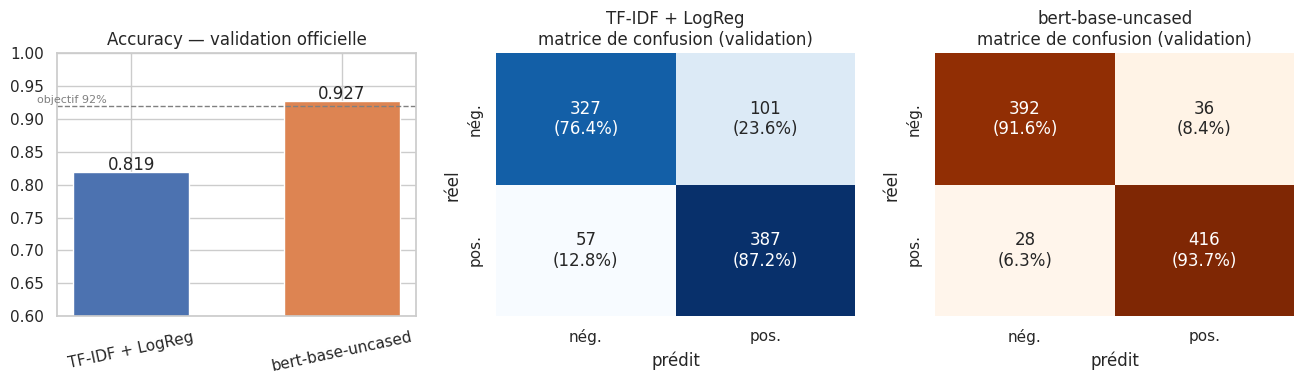

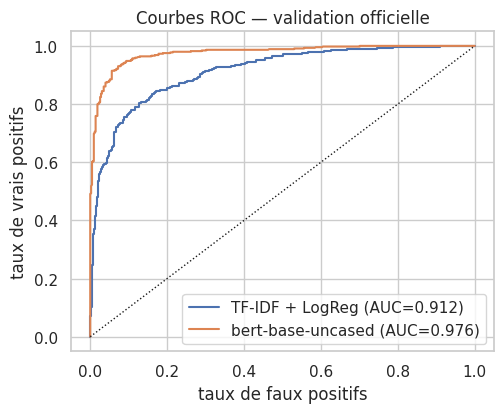

In [23]:
colors_ = {"tfidf": BLUE, "bert": ORANGE}
fig, axes = plt.subplots(1, 1 + len(R), figsize=(4.4 * (1 + len(R)), 4))
acc = {NAMES[k]: R[k][0]["val"]["accuracy"] for k in R}
axes[0].bar(acc.keys(), acc.values(), color=[colors_[k] for k in R], width=.55)
for i, v in enumerate(acc.values()): axes[0].text(i, v + .004, f"{v:.3f}", ha="center")
axes[0].axhline(TARGET_VAL_ACC, ls="--", c="grey", lw=1); axes[0].text(-.45, TARGET_VAL_ACC + .004, f"objectif {TARGET_VAL_ACC:.0%}", color="grey", fontsize=8)
axes[0].set(ylim=(.6, 1), title="Accuracy — validation officielle"); axes[0].tick_params(axis="x", rotation=12)
for ax, k in zip(axes[1:], R):
    v = R[k][1]["val"]; cm = confusion_matrix(v.label, v.pred)
    sns.heatmap(cm, annot=[[f"{n}\n({n/cm[i].sum():.1%})" for n in row] for i, row in enumerate(cm)], fmt="", cmap="Blues" if k == "tfidf" else "Oranges", cbar=False, ax=ax,
                xticklabels=["nég.", "pos."], yticklabels=["nég.", "pos."]); ax.set(title=f"{NAMES[k]}\nmatrice de confusion (validation)", xlabel="prédit", ylabel="réel")
plt.tight_layout(); plt.savefig(OUT / "report_overview.png", dpi=130); plt.show()

plt.figure(figsize=(5.2, 4.3))
for k in R:
    v = R[k][1]["val"]; fpr, tpr, _ = roc_curve(v.label, v.proba)
    plt.plot(fpr, tpr, color=colors_[k], label=f"{NAMES[k]} (AUC={roc_auc_score(v.label, v.proba):.3f})")
plt.plot([0, 1], [0, 1], "k:", lw=1); plt.xlabel("taux de faux positifs"); plt.ylabel("taux de vrais positifs"); plt.title("Courbes ROC — validation officielle"); plt.legend(loc="lower right")
plt.tight_layout(); plt.savefig(OUT / "report_roc.png", dpi=130); plt.show()

In [24]:
# ---------- Tests statistiques sur la validation officielle (plan apparié) ----------
from scipy.stats import binomtest
def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; d = 1 + z * z / n; c = p + z * z / (2 * n); h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)); return (c - h) / d, (c + h) / d
def paired_boot(ok_a, ok_b, n_boot=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed); n = len(ok_a); idx = rng.integers(0, n, (n_boot, n))
    d = ok_b[idx].mean(1) - ok_a[idx].mean(1); return np.percentile(d, [2.5, 97.5])

STATS = {}
for k in R:
    v = R[k][1]["val"]; ok = (v.pred == v.label).values; n = len(ok)
    STATS[k] = dict(acc=ok.mean(), wilson=wilson(int(ok.sum()), n))
display(Markdown("**Accuracy de validation avec intervalle de confiance de Wilson à 95 %** : " + " · ".join(
    f"{NAMES[k]} = {STATS[k]['acc']:.2%} [{STATS[k]['wilson'][0]:.2%} ; {STATS[k]['wilson'][1]:.2%}]" for k in R)))

if HAS_BERT:
    pb, pt = R["tfidf"][1]["val"], R["bert"][1]["val"]
    assert len(pb) == len(pt) and (pb.idx.values == pt.idx.values).all() and (pb.label.values == pt.label.values).all(), "les prédictions doivent porter sur les mêmes exemples (plan apparié)"
    ok_b, ok_t = (pb.pred == pb.label).values, (pt.pred == pt.label).values
    b, c = int((ok_b & ~ok_t).sum()), int((~ok_b & ok_t).sum())               # b : baseline seule juste ; c : BERT seul juste
    p_mcnemar = binomtest(c, b + c, 0.5).pvalue if b + c else 1.0
    lo, hi = paired_boot(ok_b, ok_t); diff = ok_t.mean() - ok_b.mean()
    display(pd.DataFrame({"": ["BERT juste / baseline fausse (c)", "baseline juste / BERT faux (b)", "les deux justes", "les deux faux"],
                          "phrases": [c, b, int((ok_b & ok_t).sum()), int((~ok_b & ~ok_t).sum())]}).style.hide(axis="index"))
    display(Markdown(f"**Test de McNemar exact** (n = {len(pb)} paires ; seules les {b + c} paires discordantes comptent) : p = **{p_mcnemar:.2e}**  \n"
                     f"**Écart d'accuracy BERT − baseline** : {diff:+.4f} — IC 95 % bootstrap apparié ({N_BOOT} rééchantillonnages) : [{lo:+.4f} ; {hi:+.4f}]"))
    display(Markdown("*Limites.* Le test suppose des exemples indépendants (vrai pour des phrases de validation distinctes) et ne porte que sur **cette** paire de modèles entraînés avec **une** graine : "
                     "il mesure l'incertitude liée à l'échantillon de 872 phrases, pas celle liée à l'aléa de l'entraînement."))

**Accuracy de validation avec intervalle de confiance de Wilson à 95 %** : TF-IDF + LogReg = 81.88% [79.19% ; 84.30%] · bert-base-uncased = 92.66% [90.74% ; 94.21%]

,phrases
BERT juste / baseline fausse (c),122
baseline juste / BERT faux (b),28
les deux justes,686
les deux faux,36


**Test de McNemar exact** (n = 872 paires ; seules les 150 paires discordantes comptent) : p = **3.43e-15**  
**Écart d'accuracy BERT − baseline** : +0.1078 — IC 95 % bootstrap apparié (5000 rééchantillonnages) : [+0.0814 ; +0.1342]

*Limites.* Le test suppose des exemples indépendants (vrai pour des phrases de validation distinctes) et ne porte que sur **cette** paire de modèles entraînés avec **une** graine : il mesure l'incertitude liée à l'échantillon de 872 phrases, pas celle liée à l'aléa de l'entraînement.

### 8.1 · Comparaison élargie et coût d'inférence
Le premier tableau réunit tous les modèles évalués sur la validation officielle, avec l'intervalle de Wilson à 95 %. Les tests appariés (McNemar exact et IC bootstrap de l'écart) comparent ensuite BERT fine-tuné à la meilleure variante gelée, choisie sur `dev`, puis cette variante à TF-IDF. On mesure enfin le temps de prédiction des 872 phrases et la taille des deux modèles principaux, puisque le choix d'un modèle ne se fait pas sur l'accuracy seule.

In [25]:
def pair_test(key_a, key_b):
    """McNemar exact et IC bootstrap apparié de l'écart d'accuracy (b − a) sur la validation officielle."""
    A = pd.read_csv(OUT / f"{key_a}_val_preds.csv"); B_ = pd.read_csv(OUT / f"{key_b}_val_preds.csv")
    assert (A.idx.values == B_.idx.values).all(), "plan apparié : mêmes phrases dans le même ordre"
    ok_a, ok_b = (A.pred == A.label).values, (B_.pred == B_.label).values
    n10, n01 = int((ok_a & ~ok_b).sum()), int((~ok_a & ok_b).sum())
    p = binomtest(n01, n10 + n01, 0.5).pvalue if n10 + n01 else 1.0
    lo_, hi_ = paired_boot(ok_a, ok_b)
    return {"a": key_a, "b": key_b, "acc_a": float(ok_a.mean()), "acc_b": float(ok_b.mean()),
            "ecart": float(ok_b.mean() - ok_a.mean()), "ic_bas": float(lo_), "ic_haut": float(hi_),
            "a_seul_juste": n10, "b_seul_juste": n01, "p_mcnemar": float(p)}

MODEL_LABELS = {"tfidf": "TF-IDF + LogReg", "frozen_cls": "BERT gelé, [CLS] + LogReg",
                "frozen_mean": "BERT gelé, moyenne + LogReg", "distilbert": "DistilBERT fine-tuné", "bert": "BERT fine-tuné"}
dispo = [k for k in MODEL_LABELS if (OUT / f"{k}_val_preds.csv").exists()]
tab = []
for k in dispo:
    v = pd.read_csv(OUT / f"{k}_val_preds.csv"); ok_ = (v.pred == v.label).values
    lo_w_, hi_w_ = wilson(int(ok_.sum()), len(ok_))
    tab.append({"modèle": MODEL_LABELS[k], "accuracy": ok_.mean(), "IC95 Wilson": f"[{lo_w_:.3f} ; {hi_w_:.3f}]",
                "F1 (positif)": f1_score(v.label, v.pred), "ROC-AUC": roc_auc_score(v.label, v.proba)})
display(pd.DataFrame(tab).style.format({"accuracy": "{:.4f}", "F1 (positif)": "{:.4f}", "ROC-AUC": "{:.4f}"}).hide(axis="index"))

PAIRS = []
gelees = [k for k in ("frozen_cls", "frozen_mean") if k in dispo]
if gelees:
    BEST_FROZEN = max(gelees, key=lambda k: json.load(open(OUT / f"{k}_metrics.json"))["dev"]["accuracy"])  # choix sur dev
    if "bert" in dispo:
        PAIRS.append(pair_test(BEST_FROZEN, "bert"))
    PAIRS.append(pair_test("tfidf", BEST_FROZEN))
if "distilbert" in dispo and "bert" in dispo:
    PAIRS.append(pair_test("distilbert", "bert"))
if PAIRS:
    json.dump(PAIRS, open(OUT / "comparaisons_appariees.json", "w"), indent=2)
    display(pd.DataFrame(PAIRS).assign(a=lambda d: d.a.map(MODEL_LABELS), b=lambda d: d.b.map(MODEL_LABELS))
            .style.format({"acc_a": "{:.4f}", "acc_b": "{:.4f}", "ecart": "{:+.4f}", "ic_bas": "{:+.4f}",
                           "ic_haut": "{:+.4f}", "p_mcnemar": "{:.2e}"}).hide(axis="index"))

modèle,accuracy,IC95 Wilson,F1 (positif),ROC-AUC
TF-IDF + LogReg,0.8188,[0.792 ; 0.843],0.8305,0.9122
"BERT gelé, [CLS] + LogReg",0.8635,[0.839 ; 0.885],0.8676,0.9367
"BERT gelé, moyenne + LogReg",0.8532,[0.828 ; 0.875],0.8584,0.9367
BERT fine-tuné,0.9266,[0.907 ; 0.942],0.9286,0.9755


a,b,acc_a,acc_b,ecart,ic_bas,ic_haut,a_seul_juste,b_seul_juste,p_mcnemar
"BERT gelé, moyenne + LogReg",BERT fine-tuné,0.8532,0.9266,+0.0734,+0.0516,+0.0940,17,81,3.62e-11
TF-IDF + LogReg,"BERT gelé, moyenne + LogReg",0.8188,0.8532,+0.0344,+0.0069,+0.0631,64,94,2.08e-02


In [26]:
# ---------- Coût d'inférence sur les 872 phrases de validation ----------
COUT = {"device": device}
durees_ = []
for _ in range(6):                                                       # 1 préchauffage + médiane de 5 mesures
    t0 = time.perf_counter(); clf.predict_proba(vec.transform(val_df.sentence)); durees_.append(time.perf_counter() - t0)
COUT["tfidf_s"] = float(np.median(durees_[1:]))
COUT["tfidf_params"] = int(clf.coef_.size + clf.intercept_.size)
if BERT_AVAILABLE:
    bert_ft = load_best_bert("main")
    # Ces passages sur la validation servent au chronométrage et au contrôle du rechargement : aucune décision n'en dépend.
    evaluate(bert_ft, val_df)                                            # préchauffage (chargement des noyaux GPU)
    if device == "cuda": torch.cuda.synchronize()
    t0 = time.perf_counter(); _, p_check = evaluate(bert_ft, val_df)
    if device == "cuda": torch.cuda.synchronize()
    COUT["bert_s"] = time.perf_counter() - t0
    COUT["bert_params"] = int(sum(p.numel() for p in bert_ft.parameters()))
    COUT["bert_mo_float32"] = COUT["bert_params"] * 4 / 1e6
    COUT["ratio_temps"] = COUT["bert_s"] / COUT["tfidf_s"]
    COUT["ecart_max_rechargement"] = float(np.abs(pd.read_csv(OUT / "bert_val_preds.csv").proba.values - p_check).max())
    assert COUT["ecart_max_rechargement"] < 1e-2, "le checkpoint rechargé ne reproduit pas les prédictions enregistrées"
    del bert_ft
    free_gpu()
json.dump(COUT, open(OUT / "cout_metrics.json", "w"), indent=2)
display(pd.DataFrame([{"modèle": "TF-IDF + LogReg", "paramètres": COUT["tfidf_params"], "prédiction des 872 phrases (s)": COUT["tfidf_s"], "matériel": "CPU"}]
                     + ([{"modèle": "BERT fine-tuné", "paramètres": COUT["bert_params"], "prédiction des 872 phrases (s)": COUT["bert_s"], "matériel": device.upper()}] if "bert_s" in COUT else []))
        .style.format({"paramètres": "{:,}", "prédiction des 872 phrases (s)": "{:.3f}"}).hide(axis="index"))
if "bert_s" in COUT:
    print(f"Contrôle : le checkpoint rechargé reproduit les probabilités enregistrées (écart max {COUT['ecart_max_rechargement']:.1e}).")

modèle,paramètres,prédiction des 872 phrases (s),matériel
TF-IDF + LogReg,"71,018",0.021,CPU
BERT fine-tuné,"109,483,778",0.634,CUDA


Contrôle : le checkpoint rechargé reproduit les probabilités enregistrées (écart max 3.0e-08).


## 9 · Analyse des erreurs
**Cadre.** On sépare strictement :
* les **observations** — quantités calculées sur la validation officielle, avec incertitude ;
* les **hypothèses explicatives** — pistes plausibles, **non démontrées** ici (aucune expérience ne teste par exemple le rôle de l'attention ; on n'affirme donc aucun mécanisme).

Les sous-groupes (longueur, négation, opposition) sont définis **par mots-clés** : approximation raisonnable mais imparfaite. Ils sont **exploratoires** : peu d'exemples par groupe, pas de correction pour comparaisons multiples.

,n,acc TF-IDF + LogReg,IC95 TF-IDF + LogReg,acc BERT,IC95 BERT,écart BERT − base,IC95 écart (bootstrap)
sous-groupe,,,,,,,
toutes les phrases,872,0.819,[0.792 ; 0.843],0.927,[0.907 ; 0.942],+0.108,[+0.081 ; +0.134]
≤ 10 mots,152,0.875,[0.813 ; 0.918],0.947,[0.900 ; 0.973],+0.072,[+0.020 ; +0.132]
11–20 mots,340,0.844,[0.802 ; 0.879],0.915,[0.880 ; 0.940],+0.071,[+0.029 ; +0.112]
21–30 mots,275,0.785,[0.733 ; 0.830],0.924,[0.886 ; 0.950],+0.138,[+0.091 ; +0.189]
> 30 mots,105,0.743,[0.652 ; 0.817],0.943,[0.881 ; 0.974],+0.200,[+0.124 ; +0.276]
sans négation,676,0.839,[0.809 ; 0.865],0.938,[0.917 ; 0.954],+0.099,[+0.071 ; +0.127]
avec négation,196,0.750,[0.685 ; 0.805],0.888,[0.836 ; 0.925],+0.138,[+0.071 ; +0.204]
sans opposition,731,0.832,[0.803 ; 0.857],0.929,[0.908 ; 0.945],+0.097,[+0.070 ; +0.126]
avec opposition,141,0.752,[0.674 ; 0.816],0.915,[0.857 ; 0.951],+0.163,[+0.085 ; +0.241]


*Lecture : un écart dont l'IC95 % exclut 0 est compatible avec une vraie différence entre modèles dans ce sous-groupe ; un IC large (petit n) ne permet pas de conclure.*

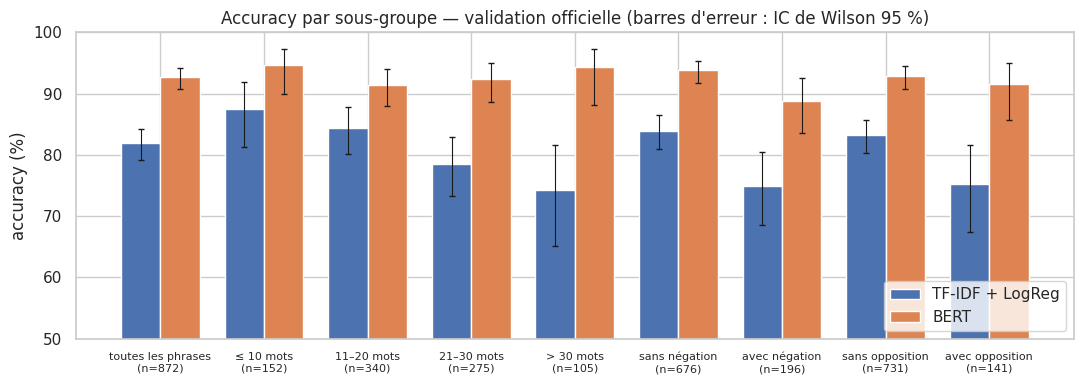

In [27]:
# ---------- 9.1 Table d'analyse (validation officielle) ----------
T = R["tfidf"][1]["val"].rename(columns={"proba": "p_tfidf", "pred": "pred_tfidf"}).copy()
if HAS_BERT:
    B = R["bert"][1]["val"]; assert (B.idx.values == T.idx.values).all()
    T["p_bert"], T["pred_bert"] = B.proba.values, B.pred.values
MODELS = ["tfidf"] + (["bert"] if HAS_BERT else []); LAB = {"tfidf": "TF-IDF + LogReg", "bert": "BERT"}
T["n_words"] = T.sentence.str.split().str.len()
T["negation"] = T.sentence.str.contains(NEG, regex=True); T["contrast"] = T.sentence.str.contains(CON, regex=True)
T["len_bucket"] = pd.cut(T.n_words, [0, 10, 20, 30, 500], labels=["≤ 10 mots", "11–20 mots", "21–30 mots", "> 30 mots"])
for m in MODELS: T[f"ok_{m}"] = (T[f"pred_{m}"] == T.label).values

groups = {"toutes les phrases": pd.Series(True, index=T.index), "≤ 10 mots": T.len_bucket == "≤ 10 mots", "11–20 mots": T.len_bucket == "11–20 mots",
          "21–30 mots": T.len_bucket == "21–30 mots", "> 30 mots": T.len_bucket == "> 30 mots",
          "sans négation": ~T.negation, "avec négation": T.negation, "sans opposition": ~T.contrast, "avec opposition": T.contrast}
rows = []
for name, mask in groups.items():
    r = {"sous-groupe": name, "n": int(mask.sum())}
    for m in MODELS:
        k = int(T.loc[mask, f"ok_{m}"].sum()); lo_, hi_ = wilson(k, int(mask.sum())); r[f"acc {LAB[m]}"] = k / max(int(mask.sum()), 1); r[f"IC95 {LAB[m]}"] = f"[{lo_:.3f} ; {hi_:.3f}]"
    if HAS_BERT and mask.sum() > 1:
        l_, h_ = paired_boot(T.loc[mask, "ok_tfidf"].values, T.loc[mask, "ok_bert"].values); r["écart BERT − base"] = r["acc BERT"] - r["acc TF-IDF + LogReg"]; r["IC95 écart (bootstrap)"] = f"[{l_:+.3f} ; {h_:+.3f}]"
    rows.append(r)
G = pd.DataFrame(rows).set_index("sous-groupe")
fmt = {c: "{:.3f}" for c in G.columns if c.startswith("acc")}; fmt.update({"écart BERT − base": "{:+.3f}"})
display(G.style.format(fmt))
display(Markdown("*Lecture : un écart dont l'IC95 % exclut 0 est compatible avec une vraie différence entre modèles dans ce sous-groupe ; un IC large (petit n) ne permet pas de conclure.*"))

x = np.arange(len(G)); w = .38; fig, ax = plt.subplots(figsize=(11, 4))
for j, m in enumerate(MODELS):
    acc_ = G[f"acc {LAB[m]}"].values; ci = np.array([wilson(int(round(a * n)), int(n)) for a, n in zip(acc_, G.n.values)])
    ax.bar(x + (j - (len(MODELS) - 1) / 2) * w, acc_ * 100, w, color=[BLUE, ORANGE][j], label=LAB[m], yerr=[(acc_ - ci[:, 0]) * 100, (ci[:, 1] - acc_) * 100], capsize=2, error_kw=dict(lw=.8))
ax.set_xticks(x); ax.set_xticklabels([f"{i}\n(n={int(n)})" for i, n in zip(G.index, G.n)], fontsize=8); ax.set(ylim=(50, 100), ylabel="accuracy (%)", title="Accuracy par sous-groupe — validation officielle (barres d'erreur : IC de Wilson 95 %)"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(OUT / "error_analysis_subgroups.png", dpi=130); plt.show()

In [28]:
# ---------- 9.2 Association erreurs ↔ marqueurs (exploratoire) ----------
from scipy.stats import fisher_exact
rows = []
for m in MODELS:
    for flag, label in [("negation", "négation"), ("contrast", "opposition"), ("long", "> 30 mots")]:
        f = (T.n_words > 30) if flag == "long" else T[flag]
        err = ~T[f"ok_{m}"]; tab = [[int((err & f).sum()), int((err & ~f).sum())], [int((~err & f).sum()), int((~err & ~f).sum())]]
        odds, p = fisher_exact(tab)
        rows.append({"modèle": LAB[m], "marqueur": label, "taux d'erreur avec": tab[0][0] / max(f.sum(), 1), "taux d'erreur sans": tab[0][1] / max((~f).sum(), 1), "rapport de cotes": odds, "p (Fisher)": p})
assoc = pd.DataFrame(rows); display(assoc.style.format({"taux d'erreur avec": "{:.1%}", "taux d'erreur sans": "{:.1%}", "rapport de cotes": "{:.2f}", "p (Fisher)": "{:.3g}"}).hide(axis="index"))
display(Markdown("*Observation seulement : une association statistique entre un marqueur et les erreurs n'établit pas que ce marqueur **cause** l'erreur (les phrases à négation sont aussi plus longues, plus nuancées, etc.).*"))

modèle,marqueur,taux d'erreur avec,taux d'erreur sans,rapport de cotes,p (Fisher)
TF-IDF + LogReg,négation,25.0%,16.1%,1.73,0.00604
TF-IDF + LogReg,opposition,24.8%,16.8%,1.63,0.0311
TF-IDF + LogReg,> 30 mots,25.7%,17.1%,1.68,0.0418
BERT,négation,11.2%,6.2%,1.91,0.0281
BERT,opposition,8.5%,7.1%,1.21,0.596
BERT,> 30 mots,5.7%,7.6%,0.74,0.689


*Observation seulement : une association statistique entre un marqueur et les erreurs n'établit pas que ce marqueur **cause** l'erreur (les phrases à négation sont aussi plus longues, plus nuancées, etc.).*

In [29]:
# ---------- 9.3 Exemples concrets, annotés automatiquement ----------
def tags(r):
    t = [x for x, c in [("négation", r.negation), ("opposition", r.contrast), ("longue (>30 mots)", r.n_words > 30), ("courte (≤10 mots)", r.n_words <= 10)] if c]
    return ", ".join(t) if t else "—"
def verb(p): return f"positif (p={p:.2f})" if p >= .5 else f"négatif (p={p:.2f})"
def show(df, title, n=8, order=None, cols=None):
    display(Markdown(f"#### {title}  *(n = {len(df)})*"))
    if len(df) == 0: print("aucun cas."); return
    d = df.sort_values(order, ascending=False).head(n) if order is not None else df.head(n)
    d = d.assign(vraie_classe=d.label.map({0: "négatif", 1: "positif"}), marqueurs=d.apply(tags, axis=1))
    display(d[["sentence", "vraie_classe", "marqueurs"] + cols].round(2))

if HAS_BERT:
    T["gain"] = (T.p_bert - T.p_tfidf).abs()
    show(T[~T.ok_tfidf & T.ok_bert], "La baseline échoue, BERT réussit (écarts de probabilité les plus nets)", order="gain", cols=["p_tfidf", "p_bert"])
    show(T[T.ok_tfidf & ~T.ok_bert], "BERT échoue, la baseline réussit", order="gain", cols=["p_tfidf", "p_bert"])
    both = T[~T.ok_tfidf & ~T.ok_bert].assign(conf=lambda d: (d.p_bert - .5).abs()); show(both, "Les deux modèles échouent (les plus confiantes en premier)", order="conf", cols=["p_tfidf", "p_bert"])
    errs = T[~T.ok_bert].assign(conf=lambda d: (d.p_bert - .5).abs()); show(errs, "Erreurs de BERT les plus confiantes", order="conf", cols=["p_bert"])
else:
    errs = T[~T.ok_tfidf].assign(conf=lambda d: (d.p_tfidf - .5).abs()); show(errs, "Erreurs les plus confiantes de la baseline", order="conf", cols=["p_tfidf"])

#### La baseline échoue, BERT réussit (écarts de probabilité les plus nets)  *(n = 122)*

,sentence,vraie_classe,marqueurs,p_tfidf,p_bert
402,"however it may please those who love movies that blare with pop songs , young science fiction fans will st...",négatif,opposition,1.00,0.01
173,"determined to be fun , and bouncy , with energetic musicals , the humor did n't quite engage this adult .",négatif,négation,1.00,0.02
719,"whaley 's determination to immerse you in sheer , unrelenting wretchedness is exhausting .",négatif,—,0.99,0.01
382,a great ensemble cast ca n't lift this heartfelt enterprise out of the familiar .,négatif,négation,0.99,0.03
560,do n't be fooled by the impressive cast list - eye see you is pure junk .,négatif,négation,0.98,0.03
398,"despite its title , punch-drunk love is never heavy-handed .",positif,"négation, opposition, courte (≤10 mots)",0.03,0.98
145,the best that can be said about the work here of scottish director ritchie ... is that he obviously does n...,négatif,négation,0.98,0.03
863,"while it 's genuinely cool to hear characters talk about early rap records ( sugar hill gang , etc. ) , th...",négatif,longue (>30 mots),0.96,0.02


#### BERT échoue, la baseline réussit  *(n = 28)*

,sentence,vraie_classe,marqueurs,p_tfidf,p_bert
580,"it takes a certain kind of horror movie to qualify as ` worse than expected , ' but ghost ship somehow man...",négatif,opposition,0.04,0.98
764,"movie fans , get ready to take off ... the other direction .",négatif,—,0.08,0.99
464,intriguing documentary which is emotionally diluted by focusing on the story 's least interesting subject .,positif,—,0.91,0.00
626,this flick is about as cool and crowd-pleasing as a documentary can get .,positif,—,0.94,0.04
230,reign of fire looks as if it was made without much thought -- and is best watched that way .,positif,négation,0.89,0.01
509,a movie that successfully crushes a best selling novel into a timeframe that mandates that you avoid the g...,positif,—,0.94,0.09
707,no telegraphing is too obvious or simplistic for this movie .,négatif,négation,0.00,0.83
142,what better message than ` love thyself ' could young women of any size receive ?,positif,—,0.96,0.16


#### Les deux modèles échouent (les plus confiantes en premier)  *(n = 36)*

,sentence,vraie_classe,marqueurs,p_tfidf,p_bert
183,"the lower your expectations , the more you 'll enjoy it .",négatif,—,0.95,1.0
791,it 's somewhat clumsy and too lethargically paced -- but its story about a mysterious creature with psychi...,négatif,"opposition, longue (>30 mots)",0.81,1.0
95,this riveting world war ii moral suspense story deals with the shadow side of american culture : racial pr...,négatif,—,0.61,1.0
519,moretti 's compelling anatomy of grief and the difficult process of adapting to loss .,négatif,—,0.60,1.0
544,"although huppert 's intensity and focus has a raw exhilaration about it , the piano teacher is anything bu...",négatif,opposition,1.00,1.0
282,"while there 's something intrinsically funny about sir anthony hopkins saying ` get in the car , bitch , '...",positif,—,0.37,0.0
695,"sit through this one , and you wo n't need a magic watch to stop time ; your dvd player will do it for you .",négatif,négation,0.98,1.0
699,"... routine , harmless diversion and little else .",positif,courte (≤10 mots),0.01,0.0


#### Erreurs de BERT les plus confiantes  *(n = 64)*

,sentence,vraie_classe,marqueurs,p_bert
183,"the lower your expectations , the more you 'll enjoy it .",négatif,—,1.0
791,it 's somewhat clumsy and too lethargically paced -- but its story about a mysterious creature with psychi...,négatif,"opposition, longue (>30 mots)",1.0
95,this riveting world war ii moral suspense story deals with the shadow side of american culture : racial pr...,négatif,—,1.0
519,moretti 's compelling anatomy of grief and the difficult process of adapting to loss .,négatif,—,1.0
544,"although huppert 's intensity and focus has a raw exhilaration about it , the piano teacher is anything bu...",négatif,opposition,1.0
282,"while there 's something intrinsically funny about sir anthony hopkins saying ` get in the car , bitch , '...",positif,—,0.0
695,"sit through this one , and you wo n't need a magic watch to stop time ; your dvd player will do it for you .",négatif,négation,1.0
464,intriguing documentary which is emotionally diluted by focusing on the story 's least interesting subject .,positif,—,0.0


In [30]:
# ---------- 9.4 Observations calculées sur les erreurs (support empirique des hypothèses) ----------
def err_profile(m):
    e = T[~T[f"ok_{m}"]]; conf = (e[f"p_{m}"] - .5).abs()
    fp = int(((e[f"pred_{m}"] == 1) & (e.label == 0)).sum()); fn = int(((e[f"pred_{m}"] == 0) & (e.label == 1)).sum())
    return {"modèle": LAB[m], "erreurs": len(e), "taux d'erreur": len(e) / len(T), "faux positifs": fp, "faux négatifs": fn,
            "% d'erreurs « confiantes » (p ≥ 0,9 ou ≤ 0,1)": (conf >= .4).mean() * 100 if len(e) else np.nan,
            "% d'erreurs avec négation": e.negation.mean() * 100 if len(e) else np.nan, "% d'erreurs avec opposition": e.contrast.mean() * 100 if len(e) else np.nan}
prof = pd.DataFrame([err_profile(m) for m in MODELS]); display(prof.style.format({"taux d'erreur": "{:.1%}", **{c: "{:.1f}" for c in prof.columns if c.startswith("%")}}).hide(axis="index"))
display(Markdown(f"Pour référence, sur l'ensemble de la validation : {T.negation.mean():.1%} des phrases contiennent une négation et {T.contrast.mean():.1%} une opposition."))

modèle,erreurs,taux d'erreur,faux positifs,faux négatifs,"% d'erreurs « confiantes » (p ≥ 0,9 ou ≤ 0,1)",% d'erreurs avec négation,% d'erreurs avec opposition
TF-IDF + LogReg,158,18.1%,101,57,25.3,31.0,22.2
BERT,64,7.3%,36,28,62.5,34.4,18.8


Pour référence, sur l'ensemble de la validation : 22.5% des phrases contiennent une négation et 16.2% une opposition.

### Hypothèses explicatives (à distinguer des observations ci-dessus)
Les pistes suivantes sont **plausibles mais non démontrées** par ce notebook. Pour chacune, la dernière colonne indique ce que les **chiffres de la section 9** peuvent (ou non) apporter ; la **lecture manuelle** des exemples reste nécessaire pour trancher.

| # | Hypothèse | Observation qui la soutiendrait | Ce qui la mettrait en doute |
|---|---|---|---|
| H1 | Un modèle « sac de n-grammes » gère mal les **négations / oppositions** car il ignore l'ordre et la portée des mots. | Écart de précision baseline − BERT plus fort **avec** que **sans** marqueur, IC95 % excluant 0 (tableau 9.1) ; taux d'erreur de la baseline plus élevé avec marqueur (9.2). | Écart comparable avec et sans marqueur ; IC larges. |
| H2 | Les **phrases longues** sont plus difficiles pour la baseline (décalage syntagmes courts → phrases). | Précision de la baseline décroissante avec la longueur (9.1). | Pas de tendance nette. |
| H3 | Une part des erreurs de BERT vient de **sentiments mixtes, d'ironie ou d'étiquettes discutables**. | Erreurs **confiantes** nombreuses (9.4) dont la relecture montre un avis ambigu (9.3). | Erreurs peu confiantes, dispersées, sans motif lisible. |
| H4 | BERT tire parti de la **connaissance acquise au pré-entraînement** (vocabulaire absent du train). | Avantage de BERT sur les phrases contenant des mots hors vocabulaire du train (non testé ici). | — *non évalué : à tester par une analyse OOV dédiée.* |

**Ce que ce notebook ne montre pas** : aucun lien causal entre un mécanisme interne de BERT (par exemple l'attention) et une prédiction ; ce type d'affirmation exigerait des expériences dédiées (ablations, sondes, perturbations contrôlées).

### 9.5 · Mise à l'épreuve des hypothèses H1, H2 et H4
La section 3 a compté les mots distincts de la validation qui n'apparaissent jamais dans le train. TF-IDF ne peut rien faire de ces mots, alors que BERT les découpe en unités WordPiece rencontrées pendant son pré-entraînement. Si H4 est juste, l'avantage de BERT doit être plus grand sur les phrases qui contiennent au moins un mot absent du vocabulaire de la baseline. Ce vocabulaire est plus étroit que celui du train : TF-IDF ne garde que les mots vus au moins deux fois dans `train_fit` et ignore les mots d'une seule lettre. Le tableau 9.1 donnait un écart par sous-groupe ; pour conclure qu'un écart est *plus grand* dans un groupe qu'en dehors, il faut un intervalle de confiance sur la différence des deux écarts. La seconde cellule le calcule par bootstrap pour chaque marqueur : négation et opposition (H1), plus de 30 mots (H2), mot hors vocabulaire (H4).

In [31]:
# ---------- Mots absents du vocabulaire de la baseline (unigrammes de TF-IDF) ----------
analyseur = vec.build_analyzer()
def mots_hors_vocab(s):
    return sorted({w for w in analyseur(s) if " " not in w and w not in vec.vocabulary_})
T["oov_mots"] = T.sentence.apply(mots_hors_vocab)
T["oov"] = T.oov_mots.str.len() > 0

lignes_oov = []
for nom, masque in {"toutes les phrases": pd.Series(True, index=T.index),
                    "sans mot hors vocabulaire": ~T.oov, "avec mot hors vocabulaire": T.oov}.items():
    r = {"sous-groupe": nom, "n": int(masque.sum())}
    for m in MODELS:
        k_ = int(T.loc[masque, f"ok_{m}"].sum()); lo_, hi_ = wilson(k_, int(masque.sum()))
        r[f"acc {LAB[m]}"] = k_ / max(int(masque.sum()), 1); r[f"IC95 {LAB[m]}"] = f"[{lo_:.3f} ; {hi_:.3f}]"
    if HAS_BERT and masque.sum() > 1:
        l_, h_ = paired_boot(T.loc[masque, "ok_tfidf"].values, T.loc[masque, "ok_bert"].values)
        r["écart BERT − base"] = r["acc BERT"] - r["acc TF-IDF + LogReg"]; r["IC95 écart (bootstrap)"] = f"[{l_:+.3f} ; {h_:+.3f}]"
    lignes_oov.append(r)
G_OOV = pd.DataFrame(lignes_oov).set_index("sous-groupe")
G_OOV.to_csv(OUT / "sous_groupes_oov.csv")
display(G_OOV.style.format({**{c: "{:.3f}" for c in G_OOV.columns if c.startswith("acc")}, "écart BERT − base": "{:+.3f}"}))
OOV_STATS = {"n_avec": int(T.oov.sum()), "pct_avec": float(T.oov.mean() * 100),
             "mots_distincts": int(len(set().union(*T.oov_mots))), "vocabulaire_tfidf_unigrammes": int(sum(" " not in w for w in vec.vocabulary_))}
for m in MODELS:
    err_ = ~T[f"ok_{m}"]
    odds_, p_ = fisher_exact([[int((err_ & T.oov).sum()), int((err_ & ~T.oov).sum())],
                              [int((~err_ & T.oov).sum()), int((~err_ & ~T.oov).sum())]])
    OOV_STATS[f"{m}_acc_avec"] = float(T.loc[T.oov, f"ok_{m}"].mean()); OOV_STATS[f"{m}_acc_sans"] = float(T.loc[~T.oov, f"ok_{m}"].mean())
    OOV_STATS[f"{m}_fisher_odds"] = float(odds_); OOV_STATS[f"{m}_fisher_p"] = float(p_)
json.dump(OOV_STATS, open(OUT / "oov_metrics.json", "w"), indent=2)

,n,acc TF-IDF + LogReg,IC95 TF-IDF + LogReg,acc BERT,IC95 BERT,écart BERT − base,IC95 écart (bootstrap)
sous-groupe,,,,,,,
toutes les phrases,872,0.819,[0.792 ; 0.843],0.927,[0.907 ; 0.942],+0.108,[+0.081 ; +0.134]
sans mot hors vocabulaire,383,0.822,[0.781 ; 0.857],0.927,[0.896 ; 0.949],+0.104,[+0.068 ; +0.144]
avec mot hors vocabulaire,489,0.816,[0.779 ; 0.848],0.926,[0.900 ; 0.946],+0.110,[+0.074 ; +0.149]


In [32]:
# ---------- Différence des écarts BERT − baseline : dans le groupe contre hors du groupe ----------
def ecart_des_ecarts(masque, n_boot=N_BOOT, seed=SEED):
    """Écart (BERT − base) dans le groupe moins écart hors du groupe, avec IC bootstrap à 95 %."""
    rng_ = np.random.default_rng(seed)
    a_in, b_in = T.loc[masque, "ok_tfidf"].values, T.loc[masque, "ok_bert"].values
    a_out, b_out = T.loc[~masque, "ok_tfidf"].values, T.loc[~masque, "ok_bert"].values
    i_in = rng_.integers(0, len(a_in), (n_boot, len(a_in))); i_out = rng_.integers(0, len(a_out), (n_boot, len(a_out)))
    d = (b_in[i_in].mean(1) - a_in[i_in].mean(1)) - (b_out[i_out].mean(1) - a_out[i_out].mean(1))
    obs = (b_in.mean() - a_in.mean()) - (b_out.mean() - a_out.mean())
    return float(obs), *map(float, np.percentile(d, [2.5, 97.5]))

if HAS_BERT:
    marqueurs = {"négation (H1)": T.negation, "opposition (H1)": T.contrast,
                 "plus de 30 mots (H2)": T.n_words > 30, "mot hors vocabulaire (H4)": T.oov}
    lignes_dd = []
    for nom, masque in marqueurs.items():
        obs, lo_, hi_ = ecart_des_ecarts(masque.values)
        lignes_dd.append({"marqueur": nom, "n avec": int(masque.sum()),
                          "écart avec": T.loc[masque, "ok_bert"].mean() - T.loc[masque, "ok_tfidf"].mean(),
                          "écart sans": T.loc[~masque, "ok_bert"].mean() - T.loc[~masque, "ok_tfidf"].mean(),
                          "différence": obs, "IC95 bas": lo_, "IC95 haut": hi_,
                          "conclusion": "avantage de BERT plus grand dans le groupe" if lo_ > 0 else
                                        ("avantage plus petit dans le groupe" if hi_ < 0 else "pas de différence établie")})
    DD = pd.DataFrame(lignes_dd)
    DD.to_csv(OUT / "ecart_des_ecarts.csv", index=False)
    display(DD.style.format({"écart avec": "{:+.3f}", "écart sans": "{:+.3f}", "différence": "{:+.3f}",
                             "IC95 bas": "{:+.3f}", "IC95 haut": "{:+.3f}"}).hide(axis="index"))
    display(Markdown("*Lecture : une différence dont l'IC à 95 % exclut 0 indique que l'avantage de BERT dépend du marqueur. "
                     "Quatre comparaisons exploratoires, sans correction pour tests multiples : un résultat isolé proche du seuil reste fragile.*"))

# Table d'analyse complète de la validation, réutilisée en 9.8 et pour le rapport
T.assign(oov_mots=T.oov_mots.str.join(" ")).to_csv(OUT / "analyse_validation.csv", index=False)
G.to_csv(OUT / "sous_groupes.csv")
assoc.to_csv(OUT / "association_marqueurs.csv", index=False)
prof.to_csv(OUT / "profil_erreurs.csv", index=False)

marqueur,n avec,écart avec,écart sans,différence,IC95 bas,IC95 haut,conclusion
négation (H1),196,+0.138,+0.099,+0.039,-0.032,+0.112,pas de différence établie
opposition (H1),141,+0.163,+0.097,+0.066,-0.019,+0.149,pas de différence établie
plus de 30 mots (H2),105,+0.200,+0.095,+0.105,+0.023,+0.191,avantage de BERT plus grand dans le groupe
mot hors vocabulaire (H4),489,+0.110,+0.104,+0.006,-0.046,+0.060,pas de différence établie


*Lecture : une différence dont l'IC à 95 % exclut 0 indique que l'avantage de BERT dépend du marqueur. Quatre comparaisons exploratoires, sans correction pour tests multiples : un résultat isolé proche du seuil reste fragile.*

### 9.6 · Phrases personnelles et paires minimales
Le cours demande de tester le modèle sur ses propres phrases. On le fait de deux façons. D'abord douze phrases écrites pour l'occasion, avec des négations, des oppositions, de l'ironie et des mots rares. Ensuite des paires minimales construites à partir de gabarits. La même phrase apparaît avec et sans négation (« the movie is good », puis « the movie is not good »). Des phrases à deux propositions reliées par *but* complètent le jeu : l'avis retenu y est celui de la seconde proposition. Ces phrases isolent la négation et l'opposition, ce que les mots-clés de la section 9.1 ne permettaient pas. Elles testent H1 de façon contrôlée, sur un anglais plus simple que celui des critiques réelles. Convention d'étiquetage : une phrase niée reçoit l'étiquette inverse de l'affirmation (« not bad » compte comme positif, comme le suggère le poids très positif que la baseline donne à ce bigramme en section 5 ; « not brilliant » compte comme négatif). Ce choix se discute pour certains adjectifs et pèse sur l'accuracy des gabarits de négation. Le taux d'inversion, lui, n'en dépend pas : il dit seulement si la prédiction change quand on ajoute la négation.

In [33]:
def predict_both(texts):
    """Probabilité « positif » selon la baseline et selon BERT fine-tuné (meilleur checkpoint)."""
    out = pd.DataFrame({"phrase": texts, "p_tfidf": clf.predict_proba(vec.transform(texts))[:, 1]})
    if BERT_AVAILABLE:
        m_ = load_best_bert("main"); probs = []
        with torch.no_grad():
            for i in range(0, len(texts), EVAL_BATCH):
                b = tokenizer(texts[i:i + EVAL_BATCH], truncation=True, max_length=MAX_LEN, padding=True, return_tensors="pt").to(device)
                with autocast_ctx():
                    probs.append(torch.softmax(m_(**b).logits.float(), -1)[:, 1].cpu().numpy())
        out["p_bert"] = np.concatenate(probs)
        del m_
        free_gpu()
    return out

# ---- Phrases personnelles (étiquette attendue fixée par nous) ----
PERSO = [("this movie is not bad at all .", 1),
         ("i expected a masterpiece , and it is not even watchable .", 0),
         ("the actors are great , but the script is a disaster .", 0),
         ("the script is a disaster , but the actors are great .", 1),
         ("oh great , another two hours of my life i will never get back .", 0),
         ("a film so bad it becomes hilarious , in the best way .", 1),
         ("it is hard to imagine a less inspired sequel .", 0),
         ("not a single scene feels false .", 1),
         ("the cinematography is breathtaking ; the dialogue , sadly , is not .", 0),
         ("i laughed , i cried , i bought the soundtrack .", 1),
         ("a perfunctory , by-the-numbers thriller .", 0),
         ("an unpretentious , sweet-natured delight .", 1)]
PP = predict_both([s for s, _ in PERSO]).assign(attendu=[lab for _, lab in PERSO])
for m in [x for x in ("tfidf", "bert") if f"p_{x}" in PP]:
    PP[f"{m} juste"] = np.where((PP[f"p_{m}"] >= .5).astype(int) == PP.attendu, "oui", "non")
PP["attendu"] = PP.attendu.map({0: "négatif", 1: "positif"})
PP.to_csv(OUT / "phrases_personnelles.csv", index=False)
display(PP.style.format({c: "{:.2f}" for c in ("p_tfidf", "p_bert") if c in PP}).hide(axis="index"))

phrase,p_tfidf,p_bert,attendu,tfidf juste,bert juste
this movie is not bad at all .,0.01,1.00,positif,non,oui
"i expected a masterpiece , and it is not even watchable .",0.28,0.00,négatif,oui,oui
"the actors are great , but the script is a disaster .",0.46,0.01,négatif,oui,oui
"the script is a disaster , but the actors are great .",0.46,0.99,positif,non,oui
"oh great , another two hours of my life i will never get back .",0.56,0.05,négatif,non,oui
"a film so bad it becomes hilarious , in the best way .",0.94,0.99,positif,oui,oui
it is hard to imagine a less inspired sequel .,0.02,0.93,négatif,oui,non
not a single scene feels false .,0.00,0.02,positif,non,non
"the cinematography is breathtaking ; the dialogue , sadly , is not .",0.00,0.10,négatif,oui,oui
"i laughed , i cried , i bought the soundtrack .",1.00,1.00,positif,oui,oui


In [34]:
# ---- Paires minimales construites par gabarits ----
SUJETS = ["the movie", "this film", "the story", "the acting", "the ending"]
POSITIFS = ["good", "great", "funny", "moving", "brilliant", "enjoyable"]
NEGATIFS = ["bad", "boring", "dull", "awful", "predictable", "tedious"]
lignes_mp = []
for s in SUJETS:
    for adj, lab in [(w, 1) for w in POSITIFS] + [(w, 0) for w in NEGATIFS]:
        paire = f"{s}|{adj}"
        lignes_mp += [{"gabarit": "affirmation", "phrase": f"{s} is {adj} .", "label": lab, "paire": paire},
                      {"gabarit": "négation « not »", "phrase": f"{s} is not {adj} .", "label": 1 - lab, "paire": paire},
                      {"gabarit": "négation « n't »", "phrase": f"{s} is n't {adj} .", "label": 1 - lab, "paire": paire}]
for s1, s2 in [("the acting", "the story"), ("the music", "the plot"), ("the cast", "the script")]:
    for adj_pos in POSITIFS[:4]:                  # noms de boucle choisis pour ne pas écraser « b » (section 8)
        for adj_neg in NEGATIFS[:4]:
            lignes_mp += [{"gabarit": "opposition « + but − »", "phrase": f"{s1} is {adj_pos} , but {s2} is {adj_neg} .", "label": 0, "paire": None},
                          {"gabarit": "opposition « − but + »", "phrase": f"{s1} is {adj_neg} , but {s2} is {adj_pos} .", "label": 1, "paire": None}]
MP = pd.DataFrame(lignes_mp)
MP = pd.concat([MP, predict_both(MP.phrase.tolist()).drop(columns="phrase")], axis=1)
MODELES_MP = [m for m in ("tfidf", "bert") if f"p_{m}" in MP]
for m in MODELES_MP:
    MP[f"pred_{m}"] = (MP[f"p_{m}"] >= .5).astype(int); MP[f"ok_{m}"] = MP[f"pred_{m}"] == MP.label
MP.to_csv(OUT / "paires_minimales.csv", index=False)

resume_mp, MP_STATS = [], {}
for gab, d in MP.groupby("gabarit", sort=False):
    r = {"gabarit": gab, "n": len(d)}
    for m in MODELES_MP:
        lo_, hi_ = wilson(int(d[f"ok_{m}"].sum()), len(d))
        r[f"acc {LAB[m]}"] = d[f"ok_{m}"].mean(); r[f"IC95 {LAB[m]}"] = f"[{lo_:.2f} ; {hi_:.2f}]"
        MP_STATS[f"{m}|{gab}"] = float(d[f"ok_{m}"].mean())
    resume_mp.append(r)
# Taux d'inversion : la prédiction change-t-elle quand on ajoute la négation ?
for m in MODELES_MP:
    for gab in ["négation « not »", "négation « n't »"]:
        aff = MP[MP.gabarit == "affirmation"].set_index("paire")[f"pred_{m}"]
        neg = MP[MP.gabarit == gab].set_index("paire")[f"pred_{m}"]
        MP_STATS[f"{m}|inversion {gab}"] = float((aff != neg.loc[aff.index]).mean())
json.dump({"n_phrases": len(MP), **MP_STATS}, open(OUT / "paires_minimales_metrics.json", "w"), indent=2)
display(pd.DataFrame(resume_mp).style.format({c: "{:.2f}" for c in pd.DataFrame(resume_mp).columns if c.startswith("acc")}).hide(axis="index"))
display(pd.DataFrame([{"modèle": LAB[m], **{f"inversion {g.split(' ', 1)[1]}": MP_STATS[f"{m}|inversion {g}"]
                                            for g in ["négation « not »", "négation « n't »"]}} for m in MODELES_MP])
        .style.format({c: "{:.0%}" for c in ["inversion « not »", "inversion « n't »"]}).hide(axis="index"))
display(Markdown("*Taux d'inversion : part des paires où ajouter la négation change la prédiction. Un modèle qui traite "
                 "correctement la négation inverse sa prédiction dans 100 % des paires.*"))

gabarit,n,acc TF-IDF + LogReg,IC95 TF-IDF + LogReg,acc BERT,IC95 BERT
affirmation,60,0.95,[0.86 ; 0.98],1.00,[0.94 ; 1.00]
négation « not »,60,0.48,[0.36 ; 0.61],1.00,[0.94 ; 1.00]
négation « n't »,60,0.05,[0.02 ; 0.14],1.00,[0.94 ; 1.00]
opposition « + but − »,48,0.75,[0.61 ; 0.85],1.00,[0.93 ; 1.00]
opposition « − but + »,48,0.21,[0.12 ; 0.34],1.00,[0.93 ; 1.00]


modèle,inversion « not »,inversion « n't »
TF-IDF + LogReg,43%,0%
BERT,100%,100%


*Taux d'inversion : part des paires où ajouter la négation change la prédiction. Un modèle qui traite correctement la négation inverse sa prédiction dans 100 % des paires.*

### 9.7 · Calibration des probabilités
La section 9.4 a compté les erreurs de BERT commises avec une probabilité supérieure à 0,9 ou inférieure à 0,1. Reste à savoir si ces probabilités veulent dire quelque chose. Un modèle bien calibré qui annonce 95 % de confiance a raison 95 fois sur 100. Le diagramme de fiabilité compare, tranche par tranche de confiance, ce que le modèle annonce et ce qu'il obtient. L'erreur de calibration attendue (ECE) résume cet écart et le score de Brier mesure la qualité globale des probabilités. On essaie aussi le *temperature scaling* : un seul paramètre, ajusté sur `dev`, qui adoucit ou durcit les probabilités sans changer aucune prédiction. `dev` contient des syntagmes et la validation des phrases complètes, ce qui peut limiter le transfert de ce réglage.

,ECE,Brier,température T,ECE après T,Brier après T,% d'erreurs confiantes,confiance moyenne des erreurs
TF-IDF + LogReg,0.070,0.127,1.86,0.029,0.122,25.3,0.760
BERT,0.048,0.062,1.68,0.013,0.058,62.5,0.888


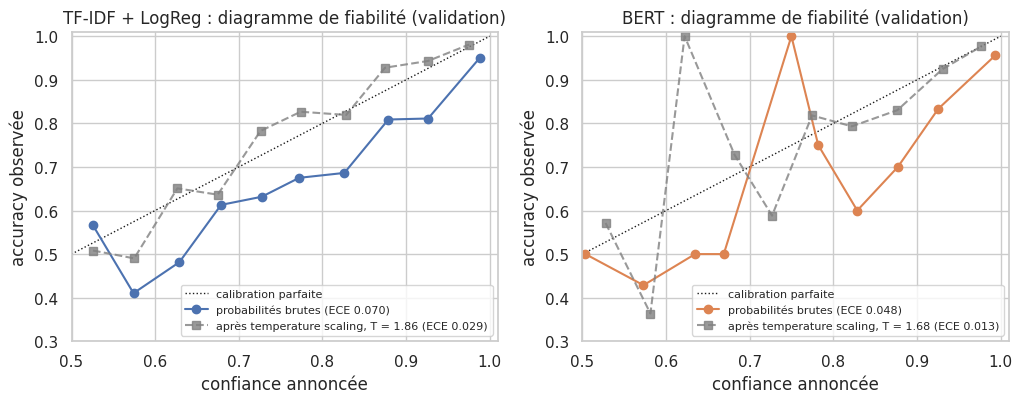

In [35]:
from scipy.optimize import minimize_scalar

def calibration(y, p, n_bins=N_CALIB_BINS):
    """ECE (confiance de la classe prédite, tranches de largeur égale sur [0,5 ; 1]), Brier, table de fiabilité."""
    y, p = np.asarray(y), np.clip(np.asarray(p, dtype=float), 1e-7, 1 - 1e-7)
    conf = np.maximum(p, 1 - p); ok = ((p >= .5).astype(int) == y)
    bornes = np.linspace(.5, 1, n_bins + 1); t = np.clip(np.digitize(conf, bornes[1:-1]), 0, n_bins - 1)
    ece, rows_ = 0.0, []
    for b in range(n_bins):
        sel = t == b
        if sel.any():
            ece += sel.mean() * abs(ok[sel].mean() - conf[sel].mean())
            rows_.append({"tranche": f"[{bornes[b]:.2f} ; {bornes[b + 1]:.2f}]", "n": int(sel.sum()),
                          "confiance moyenne": conf[sel].mean(), "accuracy": ok[sel].mean()})
    return float(ece), float(np.mean((p - y) ** 2)), pd.DataFrame(rows_)

def fit_temperature(y, p):
    """Température T qui minimise la log-vraisemblance négative de sigmoïde(logit / T) ; T > 1 adoucit."""
    y = np.asarray(y); z = np.log(np.clip(p, 1e-7, 1 - 1e-7) / (1 - np.clip(p, 1e-7, 1 - 1e-7)))
    nll = lambda logt: -np.mean(y * -np.logaddexp(0, -z / np.exp(logt)) + (1 - y) * -np.logaddexp(0, z / np.exp(logt)))
    return float(np.exp(minimize_scalar(nll, bounds=(-3, 3), method="bounded").x))

def apply_temperature(p, temp):
    z = np.log(np.clip(p, 1e-7, 1 - 1e-7) / (1 - np.clip(p, 1e-7, 1 - 1e-7)))
    return 1 / (1 + np.exp(-z / temp))

CALIB, courbes = {}, {}
for m in MODELS:
    dev_p = pd.read_csv(OUT / f"{m}_dev_preds.csv"); val_p = pd.read_csv(OUT / f"{m}_val_preds.csv")
    ece_, brier_, table_ = calibration(val_p.label, val_p.proba)
    temp_ = fit_temperature(dev_p.label.values, dev_p.proba.values)
    p_t = apply_temperature(val_p.proba.values, temp_)
    ece_t, brier_t, table_t = calibration(val_p.label, p_t)
    err_ = (val_p.pred != val_p.label).values
    conf_err = np.maximum(val_p.proba.values, 1 - val_p.proba.values)[err_]
    CALIB[m] = {"ece": ece_, "brier": brier_, "temperature": temp_, "ece_apres_T": ece_t, "brier_apres_T": brier_t,
                "pct_erreurs_confiantes": float((conf_err >= CONFIDENT).mean() * 100) if err_.any() else float("nan"),
                "confiance_moyenne_erreurs": float(conf_err.mean()) if err_.any() else float("nan")}
    courbes[m] = (table_, table_t)
json.dump(CALIB, open(OUT / "calibration_metrics.json", "w"), indent=2)
display(pd.DataFrame(CALIB).T.rename(index=LAB).rename(columns={
    "ece": "ECE", "brier": "Brier", "temperature": "température T", "ece_apres_T": "ECE après T", "brier_apres_T": "Brier après T",
    "pct_erreurs_confiantes": "% d'erreurs confiantes", "confiance_moyenne_erreurs": "confiance moyenne des erreurs"})
    .style.format({"ECE": "{:.3f}", "Brier": "{:.3f}", "température T": "{:.2f}", "ECE après T": "{:.3f}", "Brier après T": "{:.3f}",
                   "% d'erreurs confiantes": "{:.1f}", "confiance moyenne des erreurs": "{:.3f}"}))

fig, axes = plt.subplots(1, len(MODELS), figsize=(5.2 * len(MODELS), 4.2), squeeze=False)
for ax, m, col in zip(axes[0], MODELS, [BLUE, ORANGE]):
    tb, tbt = courbes[m]
    ax.plot([.5, 1], [.5, 1], "k:", lw=1, label="calibration parfaite")
    ax.plot(tb["confiance moyenne"], tb["accuracy"], "o-", color=col, label=f"probabilités brutes (ECE {CALIB[m]['ece']:.3f})")
    ax.plot(tbt["confiance moyenne"], tbt["accuracy"], "s--", color="grey", alpha=.8,
            label=f"après temperature scaling, T = {CALIB[m]['temperature']:.2f} (ECE {CALIB[m]['ece_apres_T']:.3f})")
    ax.set(title=f"{LAB[m]} : diagramme de fiabilité (validation)", xlabel="confiance annoncée", ylabel="accuracy observée",
           xlim=(.5, 1.01), ylim=(.3, 1.01)); ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "calibration.png", dpi=130); plt.show()

### 9.8 · Erreurs de BERT à relire
Le cours demande dix phrases mal classées, regroupées par cause : négation, ironie, avis mitigé, vocabulaire rare, étiquette discutable. La cellule suivante rassemble toutes les erreurs de BERT avec ce qui aide à les lire (probabilités des deux modèles, marqueurs de négation et d'opposition, mots hors vocabulaire de la baseline) et les enregistre dans `results/erreurs_bert_a_annoter.csv`. Les plus confiantes viennent en premier, car ce sont celles où le modèle se trompe sans hésiter. La lecture elle-même est présentée en section 9.9.

In [36]:
if HAS_BERT:
    ERR_BERT = (T[~T.ok_bert]
                .assign(confiance=lambda d: np.maximum(d.p_bert, 1 - d.p_bert), baseline_juste=lambda d: d.ok_tfidf,
                        oov_mots=lambda d: d.oov_mots.str.join(" "))
                .sort_values("confiance", ascending=False)
                [["idx", "sentence", "label", "p_bert", "p_tfidf", "confiance", "baseline_juste", "negation", "contrast", "n_words", "oov_mots"]])
    ERR_BERT.to_csv(OUT / "erreurs_bert_a_annoter.csv", index=False)
    print(f"{len(ERR_BERT)} erreurs de BERT enregistrées, dont {int((ERR_BERT.confiance >= CONFIDENT).sum())} "
          f"avec une confiance d'au moins {fr(CONFIDENT)}.")
    display(ERR_BERT.head(12).assign(label=lambda d: d.label.map({0: "négatif", 1: "positif"}))
            .style.format({"p_bert": "{:.3f}", "p_tfidf": "{:.3f}", "confiance": "{:.3f}"}).hide(axis="index"))

64 erreurs de BERT enregistrées, dont 40 avec une confiance d'au moins 0,9.


idx,sentence,label,p_bert,p_tfidf,confiance,baseline_juste,negation,contrast,n_words,oov_mots
183,"the lower your expectations , the more you 'll enjoy it .",négatif,0.999,0.949,0.999,False,False,False,12,
791,"it 's somewhat clumsy and too lethargically paced -- but its story about a mysterious creature with psychic abilities offers a solid build-up , a terrific climax , and some nice chills along the way .",négatif,0.999,0.805,0.999,False,False,True,36,
95,this riveting world war ii moral suspense story deals with the shadow side of american culture : racial prejudice in its ugly and diverse forms .,négatif,0.998,0.606,0.998,False,False,False,26,
519,moretti 's compelling anatomy of grief and the difficult process of adapting to loss .,négatif,0.998,0.602,0.998,False,False,False,15,adapting anatomy moretti
544,"although huppert 's intensity and focus has a raw exhilaration about it , the piano teacher is anything but fun .",négatif,0.997,1.000,0.997,False,False,True,21,exhilaration
282,"while there 's something intrinsically funny about sir anthony hopkins saying ` get in the car , bitch , ' this jerry bruckheimer production has little else to offer",positif,0.003,0.366,0.997,False,False,False,29,bitch intrinsically sir
695,"sit through this one , and you wo n't need a magic watch to stop time ; your dvd player will do it for you .",négatif,0.997,0.977,0.997,False,True,False,26,
464,intriguing documentary which is emotionally diluted by focusing on the story 's least interesting subject .,positif,0.005,0.913,0.995,True,False,False,16,diluted
699,"... routine , harmless diversion and little else .",positif,0.005,0.012,0.995,False,False,False,9,
271,as unseemly as its title suggests .,positif,0.006,0.111,0.994,False,False,False,7,


### 9.9 · Dix erreurs de BERT regroupées par cause
Lecture faite par l'équipe sur les erreurs de l'exécution ci-dessus (`results/erreurs_bert_a_annoter.csv`). Les 64 erreurs de BERT ont toutes été lues et annotées. Répartition des causes : négation (9), ironie (11), avis mitigé (14), vocabulaire rare (6), étiquette discutable (18), autre (6). Le tableau en montre dix, au moins une par cause rencontrée ; les probabilités sont celles du fichier de résultats.

| Cause | Phrase | Étiquette | P(positif) BERT | P(positif) TF-IDF | Lecture |
|---|---|---|---|---|---|
| négation | it 's everything you do n't go to the movies for . | négatif | 0,99 | 0,59 | Le « n't » retourne tout le sens ; BERT prédit pourtant positif. |
| négation | ( d ) oes n't bother being as cloying or preachy as equivalent evangelical christian movies -- maybe the filmmakers know that the likely audience will already be among the faithful . | positif | 0,04 | 0,09 | La négation fait de « cloying » et « preachy » un compliment ; BERT prédit négatif. |
| ironie | the lower your expectations , the more you 'll enjoy it . | négatif | 1,00 | 0,95 | Éloge empoisonné ; la prédiction suit le sens littéral de « enjoy it ». |
| ironie | sit through this one , and you wo n't need a magic watch to stop time ; your dvd player will do it for you . | négatif | 1,00 | 0,98 | Le film serait si lent que le lecteur DVD s'arrête de lui-même. |
| avis mitigé | it 's somewhat clumsy and too lethargically paced -- but its story about a mysterious creature with psychic abilities offers a solid build-up , a terrific climax , and some nice chills along the way . | négatif | 1,00 | 0,81 | Deux jugements autour de « but » : BERT prédit comme la seconde partie, l'étiquette suit la première. |
| avis mitigé | the longer the movie goes , the worse it gets , but it 's actually pretty good in the first few minutes . | négatif | 0,99 | 0,83 | « the worse it gets » contre « pretty good » au début : BERT prédit comme la fin de la phrase. |
| vocabulaire rare | holden caulfield did it better . | négatif | 0,96 | 0,46 | Tout repose sur Holden Caulfield, héros de « L'Attrape-cœurs » : sans la référence, la critique est invisible. |
| étiquette discutable | moretti 's compelling anatomy of grief and the difficult process of adapting to loss . | négatif | 1,00 | 0,60 | « compelling » est positif et le deuil est le sujet ; l'étiquette négative se discute. |
| étiquette discutable | while there 's something intrinsically funny about sir anthony hopkins saying ` get in the car , bitch , ' this jerry bruckheimer production has little else to offer | positif | 0,00 | 0,37 | La phrase finit sur « has little else to offer » ; l'étiquette positive se défend mal. |
| autre | this one is definitely one to skip , even for horror movie fanatics . | négatif | 0,86 | 0,38 | Avis négatif sans détour, que BERT classe positif. |

## 10 · Discussion, limites et conclusion

In [37]:
# ---------- 10.1 Vérification des objectifs (calculée) ----------
mb = R["tfidf"][0]; bv = mb["val"]["accuracy"]; n_val = len(R["tfidf"][1]["val"])
rows = [("Dataset SST-2 officiel (GLUE)", f"train {len(train_full):,} · validation {n_val} · test {N_TEST_HIDDEN} (non étiqueté, non utilisé)", "✅"),
        ("Sélection sans fuite", f"hyper-paramètres et époque choisis sur dev ({len(dev_df):,} syntagmes, groupes disjoints) ; validation évaluée une fois par modèle", "✅")]
if HAS_BERT:
    m = R["bert"][0]; mv = m["val"]["accuracy"]; lo_w, hi_w = STATS["bert"]["wilson"]
    rows += [("Modèle bert-base-uncased", f"{m['model']} · {m['epochs']} époques · {m['device'].upper()} · graine {m['seed']}", "✅" if m["model"] == "bert-base-uncased" else "⚠️ variante"),
             ("Battre TF-IDF + LogReg", f"{mv:.2%} contre {bv:.2%} (validation) ; McNemar p = {p_mcnemar:.1e} ; IC95 % de l'écart [{lo:+.3f} ; {hi:+.3f}]", "✅" if (mv > bv and p_mcnemar < .05 and lo > 0) else ("⚠️ non concluant" if mv > bv else "❌")),
             (f"~{TARGET_VAL_ACC:.0%} en validation", f"estimation ponctuelle {mv:.2%} ; IC95 % de Wilson [{lo_w:.2%} ; {hi_w:.2%}]", "✅" if mv >= TARGET_VAL_ACC - .005 else "❌"),
             ("Analyse des erreurs", "sous-groupes avec IC, exemples annotés, hypothèses séparées (section 9)", "✅")]
else:
    rows += [("Modèle bert-base-uncased", "non entraîné dans cette exécution", "❌"), (f"~{TARGET_VAL_ACC:.0%} en validation", f"seuil à battre : baseline {bv:.2%}", "⏳")]
display(pd.DataFrame(rows, columns=["Exigence", "Constat", "Statut"]).style.hide(axis="index"))

Exigence,Constat,Statut
Dataset SST-2 officiel (GLUE),"train 67,349 · validation 872 · test 1821 (non étiqueté, non utilisé)",✅
Sélection sans fuite,"hyper-paramètres et époque choisis sur dev (3,353 syntagmes, groupes disjoints) ; validation évaluée une fois par modèle",✅
Modèle bert-base-uncased,bert-base-uncased · 3 époques · CUDA · graine 42,✅
Battre TF-IDF + LogReg,92.66% contre 81.88% (validation) ; McNemar p = 3.4e-15 ; IC95 % de l'écart [+0.081 ; +0.134],✅
~92% en validation,estimation ponctuelle 92.66% ; IC95 % de Wilson [90.74% ; 94.21%],✅
Analyse des erreurs,"sous-groupes avec IC, exemples annotés, hypothèses séparées (section 9)",✅


In [38]:
# ---------- 10.2 Conclusion rédigée à partir des résultats de CETTE exécution ----------
pct = lambda x: f"{x:.1%}".replace(".", ","); pts = lambda x: f"{x*100:+.1f} pt".replace(".", ","); fm = lambda x: f"{x*100:+.1f}".replace(".", ",")
L = [f"**Baseline TF-IDF + LogReg** : {pct(bv)} d'accuracy sur la validation officielle (n = {n_val})."]
if HAS_BERT:
    L = [f"**Performance.** Sur la validation officielle (n = {n_val}), {m['model']} fine-tuné atteint **{pct(mv)}** (IC95 % [{pct(lo_w)} ; {pct(hi_w)}]) contre **{pct(bv)}** pour TF-IDF + LogReg : "
         f"écart **{pts(mv - bv)}** (IC95 % bootstrap [{fm(lo)} ; {fm(hi)}] pts, McNemar p = {p_mcnemar:.1e}). "
         f"L'objectif de ~{TARGET_VAL_ACC:.0%} est **{'atteint' if mv >= TARGET_VAL_ACC - .005 else 'non atteint'}** (estimation ponctuelle).",
         f"**Appariement.** BERT corrige **{c}** phrases mal classées par la baseline et en perd **{b}**.",
         f"**Sous-groupes (observation).** Écart d'accuracy BERT − baseline : {pts(G.loc['avec négation','écart BERT − base'])} avec négation (n = {int(G.loc['avec négation','n'])}, IC95 % {G.loc['avec négation','IC95 écart (bootstrap)']}), "
         f"{pts(G.loc['sans négation','écart BERT − base'])} sans ; {pts(G.loc['avec opposition','écart BERT − base'])} avec opposition (n = {int(G.loc['avec opposition','n'])}, IC95 % {G.loc['avec opposition','IC95 écart (bootstrap)']}) ; "
         f"{pts(G.loc['> 30 mots','écart BERT − base'])} au-delà de 30 mots (n = {int(G.loc['> 30 mots','n'])}). Les intervalles larges rappellent le faible effectif de ces sous-groupes.",
         f"**Erreurs résiduelles de BERT.** {int(prof.iloc[-1]['erreurs'])} sur {n_val} ({pct(prof.iloc[-1]['taux d' + chr(39) + 'erreur'])}), dont {prof.iloc[-1]['% d' + chr(39) + 'erreurs « confiantes » (p ≥ 0,9 ou ≤ 0,1)']:.0f} % de prédictions très confiantes : "
         "ce sont les cas à relire en priorité (hypothèse H3).",
         f"**Coût.** {m['train_minutes']:.1f} min d'entraînement sur {m['device'].upper()} (précision mixte : {m['amp']}) pour {m['n_train']:,} exemples et {m['epochs']} époques, contre quelques secondes sur CPU pour la baseline."]
display(Markdown("\n\n".join(L)))

**Performance.** Sur la validation officielle (n = 872), bert-base-uncased fine-tuné atteint **92,7%** (IC95 % [90,7% ; 94,2%]) contre **81,9%** pour TF-IDF + LogReg : écart **+10,8 pt** (IC95 % bootstrap [+8,1 ; +13,4] pts, McNemar p = 3.4e-15). L'objectif de ~92% est **atteint** (estimation ponctuelle).

**Appariement.** BERT corrige **122** phrases mal classées par la baseline et en perd **28**.

**Sous-groupes (observation).** Écart d'accuracy BERT − baseline : +13,8 pt avec négation (n = 196, IC95 % [+0.071 ; +0.204]), +9,9 pt sans ; +16,3 pt avec opposition (n = 141, IC95 % [+0.085 ; +0.241]) ; +20,0 pt au-delà de 30 mots (n = 105). Les intervalles larges rappellent le faible effectif de ces sous-groupes.

**Erreurs résiduelles de BERT.** 64 sur 872 (7,3%), dont 62 % de prédictions très confiantes : ce sont les cas à relire en priorité (hypothèse H3).

**Coût.** 10.9 min d'entraînement sur CUDA (précision mixte : float16) pour 63,620 exemples et 3 époques, contre quelques secondes sur CPU pour la baseline.

### 10.3 · Ce que les compléments ajoutent
Comme la conclusion 10.2, ce texte est produit à partir des fichiers de cette exécution : aucun chiffre n'y est écrit à la main.

In [39]:
def _lire(nom):
    f = OUT / nom
    return json.load(open(f)) if f.exists() else None

pc = lambda x, d=1: fr(100 * x, d) + " %"
L2 = []
if (OUT / "bert_seeds.csv").exists():
    sd_ = pd.read_csv(OUT / "bert_seeds.csv")
    tous = sd_.val_acc.min() >= TARGET_VAL_ACC - .005
    L2.append(f"**Graines.** Sur {len(sd_)} graines, BERT obtient en moyenne {pc(sd_.val_acc.mean())} d'accuracy de validation "
              f"(écart-type {fr_pt(100 * sd_.val_acc.std(ddof=1))}, de {pc(sd_.val_acc.min())} à {pc(sd_.val_acc.max())}). "
              f"L'objectif d'environ {pc(TARGET_VAL_ACC, 0)} est {'atteint avec chaque graine' if tous else 'manqué avec au moins une graine'}.")
fc, fmn, fb, ft = _lire("frozen_cls_metrics.json"), _lire("frozen_mean_metrics.json"), _lire("bert_metrics.json"), _lire("tfidf_metrics.json")
if fc and fmn and fb and ft:
    gele = max([fc, fmn], key=lambda r: r["dev"]["accuracy"])          # variante gelée choisie sur dev
    gain_ft = fb["val"]["accuracy"] - gele["val"]["accuracy"]
    paires_ = {(p_["a"], p_["b"]): p_ for p_ in (_lire("comparaisons_appariees.json") or [])}
    ic_txt = lambda p_: (f" (IC à 95 % de l'écart [{fr_sg(100 * p_['ic_bas'])} ; {fr_sg(100 * p_['ic_haut'])}] points, "
                         f"{'qui exclut 0' if p_['ic_bas'] > 0 or p_['ic_haut'] < 0 else 'qui contient 0'})") if p_ else ""
    pft = next((v for (a_, b_), v in paires_.items() if b_ == "bert" and a_.startswith("frozen")), None)
    pbg = next((v for (a_, b_), v in paires_.items() if a_ == "tfidf" and b_.startswith("frozen")), None)
    ic_ft, ic_bg = ic_txt(pft), ic_txt(pbg)
    L2.append(f"**BERT gelé.** Sans fine-tuning, une régression logistique sur les vecteurs de BERT atteint {pc(fc['val']['accuracy'])} "
              f"avec le jeton `[CLS]` et {pc(fmn['val']['accuracy'])} avec la moyenne des jetons, contre {pc(fb['val']['accuracy'])} "
              f"après fine-tuning complet et {pc(ft['val']['accuracy'])} pour TF-IDF. La variante gelée retenue sur `dev` "
              f"{'dépasse' if gele['val']['accuracy'] > ft['val']['accuracy'] else 'reste sous'} la baseline{ic_bg}, et le fine-tuning complet "
              + (f"lui ajoute {fr_pts(100 * gain_ft)}{ic_ft}." if gain_ft > 0
                 else "ne fait pas mieux qu'elle, ce qui signale un problème d'entraînement à examiner."))
dd = OUT / "ecart_des_ecarts.csv"
if dd.exists():
    DD_ = pd.read_csv(dd)
    morceaux = [f"{r['marqueur']} {fr_pts(100 * r['différence'])} [{fr_sg(100 * r['IC95 bas'])} ; {fr_sg(100 * r['IC95 haut'])}]"
                for _, r in DD_.iterrows()]
    etablis = DD_[DD_["IC95 bas"] > 0].marqueur.tolist()
    L2.append("**Hypothèses H1, H2 et H4.** Avantage de BERT dans le groupe moins avantage hors du groupe : "
              + " ; ".join(morceaux) + ". "
              + (f"La différence est établie au seuil de 95 % pour : {', '.join(etablis)}." if etablis
                 else "Aucune de ces différences n'est établie au seuil de 95 %."))
mp = _lire("paires_minimales_metrics.json")
if mp and "bert|inversion négation « not »" in mp:
    opp = lambda m: (mp[f"{m}|opposition « + but − »"] + mp[f"{m}|opposition « − but + »"]) / 2
    L2.append(f"**Paires minimales.** Ajouter « not » inverse la prédiction de BERT dans {pc(mp['bert|inversion négation « not »'], 0)} "
              f"des paires, contre {pc(mp['tfidf|inversion négation « not »'], 0)} pour TF-IDF. Dans les phrases « A, but B », "
              f"BERT suit l'avis de la seconde proposition dans {pc(opp('bert'), 0)} des cas, TF-IDF dans {pc(opp('tfidf'), 0)}.")
cal = _lire("calibration_metrics.json")
if cal and "bert" in cal:
    cb = cal["bert"]
    L2.append(f"**Calibration.** L'ECE de BERT vaut {fr(cb['ece'], 3)}, contre {fr(cal['tfidf']['ece'], 3)} pour TF-IDF. "
              f"Ses erreurs sont commises avec une confiance moyenne de {pc(cb['confiance_moyenne_erreurs'])}. "
              f"Le temperature scaling ajusté sur `dev` (T = {fr(cb['temperature'], 2)}) "
              f"{'ramène' if cb['ece_apres_T'] < cb['ece'] else 'porte'} l'ECE de validation à {fr(cb['ece_apres_T'], 3)}.")
co = _lire("cout_metrics.json")
if co and "bert_s" in co:
    L2.append(f"**Coût.** Prédire les 872 phrases prend {fr(co['bert_s'], 2)} s à BERT sur {co['device'].upper()} et "
              f"{fr(co['tfidf_s'], 3)} s à TF-IDF sur CPU ; BERT compte {fr(co['bert_params'] / 1e6, 0)} millions de paramètres, "
              f"la baseline {fr(co['tfidf_params'] / 1e3, 0)} milliers.")
display(Markdown("\n\n".join(L2) if L2 else "Aucun complément n'a produit de résultat dans cette exécution."))

**Graines.** Sur 3 graines, BERT obtient en moyenne 92,7 % d'accuracy de validation (écart-type 0,4 point, de 92,4 % à 93,1 %). L'objectif d'environ 92 % est atteint avec chaque graine.

**BERT gelé.** Sans fine-tuning, une régression logistique sur les vecteurs de BERT atteint 86,4 % avec le jeton `[CLS]` et 85,3 % avec la moyenne des jetons, contre 92,7 % après fine-tuning complet et 81,9 % pour TF-IDF. La variante gelée retenue sur `dev` dépasse la baseline (IC à 95 % de l'écart [+0,7 ; +6,3] points, qui exclut 0), et le fine-tuning complet lui ajoute +7,3 points (IC à 95 % de l'écart [+5,2 ; +9,4] points, qui exclut 0).

**Hypothèses H1, H2 et H4.** Avantage de BERT dans le groupe moins avantage hors du groupe : négation (H1) +3,9 points [−3,2 ; +11,2] ; opposition (H1) +6,6 points [−1,9 ; +14,9] ; plus de 30 mots (H2) +10,5 points [+2,3 ; +19,1] ; mot hors vocabulaire (H4) +0,6 point [−4,6 ; +6,0]. La différence est établie au seuil de 95 % pour : plus de 30 mots (H2).

**Paires minimales.** Ajouter « not » inverse la prédiction de BERT dans 100 % des paires, contre 43 % pour TF-IDF. Dans les phrases « A, but B », BERT suit l'avis de la seconde proposition dans 100 % des cas, TF-IDF dans 48 %.

**Calibration.** L'ECE de BERT vaut 0,048, contre 0,070 pour TF-IDF. Ses erreurs sont commises avec une confiance moyenne de 88,8 %. Le temperature scaling ajusté sur `dev` (T = 1,68) ramène l'ECE de validation à 0,013.

**Coût.** Prédire les 872 phrases prend 0,63 s à BERT sur CUDA et 0,021 s à TF-IDF sur CPU ; BERT compte 109 millions de paramètres, la baseline 71 milliers.

### 10.4 · Lien avec le cours : pré-entraînement, jeton `[CLS]` et fine-tuning
BERT arrive sur SST-2 avec ce qu'il a appris en devinant des mots masqués dans 3,3 milliards de mots de texte (MLM). Un mot absent du train n'est donc pas inconnu pour lui : WordPiece le découpe en unités vues pendant le pré-entraînement (section 6.1). Cela ne se traduit pas par un avantage mesurable : en section 9.5, l'écart entre BERT et la baseline n'est pas plus grand sur les phrases qui contiennent un mot hors vocabulaire, et H4 n'est pas confirmée. Le vecteur `[CLS]` du modèle pré-entraîné n'a été entraîné sur aucun objectif de sentiment : pendant le pré-entraînement, il sert seulement à prédire si deux phrases se suivent. Les vecteurs du BERT gelé, utilisés tels quels avec une régression logistique, font déjà mieux que TF-IDF, mais restent nettement sous la version fine-tunée. Pour la variante retenue sur `dev` (moyenne des jetons), les intervalles de confiance des deux écarts excluent 0 (sections 7.1 et 8.1). Le fine-tuning n'ajoute que 1 538 paramètres, une couche linéaire de 768 × 2 poids et 2 biais, mais il ajuste aussi les 110 M de poids du réseau avec un petit taux d'apprentissage (2 × 10⁻⁵). L'écart entre version gelée et version fine-tunée estime ce que rapporte cette adaptation de tout le réseau, avec une réserve : le classifieur posé sur les vecteurs n'est pas tout à fait le même dans les deux cas. Parmi les erreurs qui restent (section 9.9), les plus nombreuses viennent d'une étiquette discutable, d'un avis mitigé ou d'une ironie, des cas où la phrase seule ne suffit pas toujours à trancher.

### Limites
* **Une seule graine** (sauf si `RUN_EXTRA_SEEDS = True`) : les intervalles et tests mesurent l'incertitude liée à l'échantillon de validation, **pas** celle liée à l'aléa de l'entraînement.
* **Pas de test officiel** : les étiquettes du test GLUE sont inaccessibles. La validation officielle sert d'évaluation finale ; elle n'est utilisée pour **aucun choix**, mais ses 872 phrases limitent la précision (≈ ±2 points d'IC à 92 %).
* **Découpage `dev` approximatif** : le regroupement par phrases d'origine est reconstruit par inclusion de séquences de mots ; la contamination résiduelle est mesurée (section 4) mais non nulle, et `dev` (syntagmes) diffère de la validation (phrases).
* **Sous-groupes** définis par mots-clés, de petite taille, sans correction pour comparaisons multiples : indicatifs seulement.
* **Aucune conclusion causale** sur les mécanismes internes de BERT.
* **Écart avec l'édition d'origine de GLUE** : le train officiel est utilisé tel quel (hors retrait des rares doublons / contradictions / recouvrements chiffrés en section 4).

### Pistes d'amélioration
Répéter l'entraînement sur plusieurs graines et rapporter moyenne ± écart-type ; comparer `roberta-base` / `deberta-v3-base` ; ajuster `lr` ∈ {2e-5, 3e-5, 5e-5} **sur `dev`** ; *early stopping* ; analyse dédiée des mots hors vocabulaire (H4) ; annotation manuelle d'un échantillon d'erreurs avec catégorisation des causes ; soumission des prédictions du test au serveur GLUE pour une évaluation officielle.

In [40]:
# ---------- Export : tout le dossier results/ (métriques, prédictions, figures) ----------
DOWNLOAD_RESULTS = True
shutil.rmtree(CKPT_DIR, ignore_errors=True) if not SAVE_MODEL else None          # les checkpoints (~440 Mo) ne sont pas inclus dans l'archive
CKPT_DIR.mkdir(exist_ok=True)
shutil.make_archive("results_sst2", "zip", OUT)
print("Archive créée : results_sst2.zip  ->", sorted(p.name for p in OUT.iterdir() if p.is_file()))
if DOWNLOAD_RESULTS:
    try:
        from google.colab import files; files.download("results_sst2.zip")
    except ImportError:
        pass

Archive créée : results_sst2.zip  -> ['analyse_validation.csv', 'association_marqueurs.csv', 'bert_dev_preds.csv', 'bert_history.csv', 'bert_learning_curves.png', 'bert_metrics.json', 'bert_seed43_val_preds.csv', 'bert_seed44_val_preds.csv', 'bert_seeds.csv', 'bert_val_preds.csv', 'calibration.png', 'calibration_metrics.json', 'comparaisons_appariees.json', 'cout_metrics.json', 'donnees_metrics.json', 'ecart_des_ecarts.csv', 'eda_overview.png', 'eda_top_words.png', 'erreurs_bert_a_annoter.csv', 'error_analysis_subgroups.png', 'frozen_cls_dev_preds.csv', 'frozen_cls_metrics.json', 'frozen_cls_val_preds.csv', 'frozen_mean_dev_preds.csv', 'frozen_mean_metrics.json', 'frozen_mean_val_preds.csv', 'oov_metrics.json', 'paires_minimales.csv', 'paires_minimales_metrics.json', 'parametres_metrics.json', 'phrases_personnelles.csv', 'profil_erreurs.csv', 'report_overview.png', 'report_roc.png', 'sous_groupes.csv', 'sous_groupes_oov.csv', 'tfidf_dev_preds.csv', 'tfidf_metrics.json', 'tfidf_val_pred

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>